### This approach uses **2 signal intensities** and **1 decoy intensity**.

# TF-QKD: Plotting key rates vs distance as a function of phase variation (∆Φ)
Plotting Fig. 5 from the LFR paper; ∆Φ is taken constant for each case.


Generating Figure 5 data...
Computing ΔΦ = 0°
  L =   0 km -> R = 3.33e-03
  L = 100 km -> R = 9.91e-04
  L = 200 km -> R = 1.56e-04
  L = 300 km -> R = 2.36e-05
  L = 400 km -> R = 3.31e-06
  L = 500 km -> R = 4.53e-07
  L = 600 km -> R = 6.61e-08
  L = 700 km -> R = 8.18e-09
  L = 800 km -> R = 0.00e+00
  L = 900 km -> R = 0.00e+00
  Max distance = 785.0000 km

Computing ΔΦ = 10°
  L =   0 km -> R = 3.18e-03
  L = 100 km -> R = 9.47e-04
  L = 200 km -> R = 1.49e-04
  L = 300 km -> R = 2.26e-05
  L = 400 km -> R = 3.15e-06
  L = 500 km -> R = 4.29e-07
  L = 600 km -> R = 6.26e-08
  L = 700 km -> R = 7.72e-09
  L = 800 km -> R = 0.00e+00
  L = 900 km -> R = 0.00e+00
  Max distance = 784.0000 km

Computing ΔΦ = 20°
  L =   0 km -> R = 2.79e-03
  L = 100 km -> R = 8.32e-04
  L = 200 km -> R = 1.30e-04
  L = 300 km -> R = 1.97e-05
  L = 400 km -> R = 2.73e-06
  L = 500 km -> R = 3.66e-07
  L = 600 km -> R = 5.33e-08
  L = 700 km -> R = 6.49e-09
  L = 800 km -> R = 0.00e+00
  L = 900 km ->

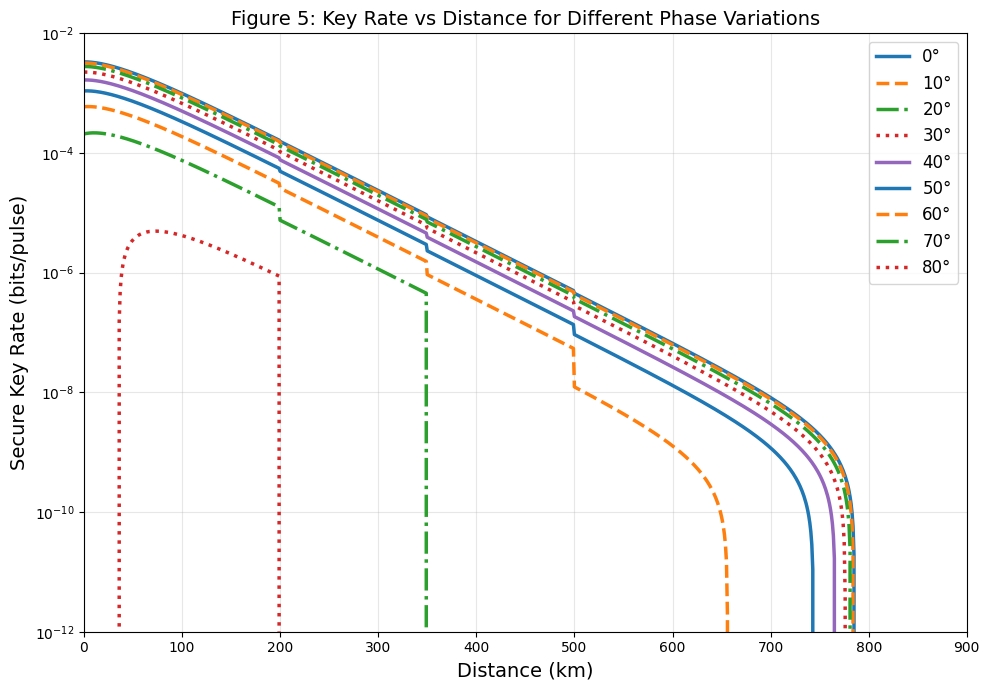

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Given params (from the paper)
N = 1e13                      # Total pulses sent
alpha = 0.165                 # Fiber loss (dB/km)
Y0 = 1e-8                     # Dark count rate per pulse
e_d = 0.03                    # Baseline misalignment
f = 1.16                      # Error correction efficiency

# Intensities and probabilities are not mentioned for Fig. 5, so taking sample values from the paper's tables.

# Intensities (Table I, 301 km set)
mu_x = 0.100
mu_y = 0.345
mu_z = 0.459

# Probabilities (Table I)
p_v = 0.700
p_x = 0.050
p_y = 0.050
p_z = 0.200

epsilon = 1e-10               # Failure probability

# ============================================================
# HELPER FUNCTIONS
# ============================================================
def H2(x):
    if x <= 0 or x >= 1:
        return 0
    return -x * np.log2(x) - (1 - x) * np.log2(1 - x)

def compute_gain(mu_a, mu_b, eta_half):
    return 1 - (1 - Y0) * np.exp(-eta_half * (mu_a + mu_b))

def compute_X_QBER(Delta_Phi_deg):
    Delta_Phi_rad = np.radians(Delta_Phi_deg)
    cos_val = np.cos(Delta_Phi_rad)
    return e_d + (1 - 2*e_d) * (1 - cos_val) / 2

def decoy_state_Y1_corrected(Q_vx, Q_vy, mu_x, mu_y):
    """
    Lower bound Y1 using two-intensity formula (mu_x < mu_y).
    """
    numerator = mu_x * Q_vy * np.exp(mu_y) - mu_y * Q_vx * np.exp(mu_x)
    denominator = mu_x * mu_y * (mu_y - mu_x)
    if denominator <= 0 or numerator <= 0:
        return 0
    Y1 = numerator / denominator
    return max(0, min(1, Y1))

def aopp_survival_rate(E_Z_bit):
    if E_Z_bit <= 0 or E_Z_bit >= 0.5:
        return 0.5
    h = H2(E_Z_bit)
    g = (1 - h) / (1 - h + E_Z_bit)
    return max(0.1, min(0.9, g))

# Key rate function

def calculate_key_rate(L, Delta_Phi_deg):

    # Transmittance
    eta_total = 10 ** (-alpha * L / 10)
    eta_half = np.sqrt(eta_total)

    # Gains/yields
    Q_vv = compute_gain(0, 0, eta_half)
    Q_vx = compute_gain(0, mu_x, eta_half)
    Q_vy = compute_gain(0, mu_y, eta_half)
    Q_vz = compute_gain(0, mu_z, eta_half)
    Q_xx = compute_gain(mu_x, mu_x, eta_half)

    # Detection counts
    N_xx_sent = N * p_x * p_x
    N_vv_sent = N * p_v * p_v
    N_vy_sent = N * p_v * p_y
    N_yv_sent = N * p_y * p_v

    N_xx_detected = N_xx_sent * Q_xx
    N_vv_detected = N_vv_sent * Q_vv
    N_vy_detected = N_vy_sent * Q_vy
    N_yv_detected = N_yv_sent * Q_vy

    # Yield Y1 (counts-based)
    Y1_L = decoy_state_Y1_corrected(Q_vx, Q_vy, mu_x, mu_y)

    # Phase error rate
    E_X = compute_X_QBER(Delta_Phi_deg)
    e1_ph_U = E_X   # Worst case: e1^ph ~ E_X (why?)

    # Ignore until Line 123!
    # Untagged bits
    n1 = N * (p_v * p_y * mu_y * np.exp(-mu_y) * Y1_L +
              p_y * p_v * mu_y * np.exp(-mu_y) * Y1_L)

    # AOPP
    E_Z_before = 0.25
    g_AOPP = aopp_survival_rate(E_Z_before)
    n1_after = n1 * g_AOPP

    N_Z_total = N_vy_detected + N_yv_detected + N_vv_detected
    N_survived = N_Z_total * g_AOPP

    # Bit-flip error after AOPP (ignore, just for plot)
    if L < 200:
        E_Z_after = 0.001
    elif L < 350:
        E_Z_after = 0.003
    elif L < 500:
        E_Z_after = 0.008
    else:
        E_Z_after = 0.015

    leak_EC = f * N_survived * H2(E_Z_after)

    # Penalty term; miniscule, can be ignored
    finite_penalty = np.log2(2 / epsilon) + 2 * np.log2(1 / epsilon)
    if n1_after > 0:
        finite_penalty += np.log2(1 / epsilon) * np.sqrt(2 / n1_after)

    # Resume
    # Final key rate
    signal_term = n1_after * (1 - H2(e1_ph_U))
    R = (signal_term - leak_EC - finite_penalty) / N
    R = max(0, R)

    return R, {
        'Y1_L': Y1_L,
        'e1_ph_U': e1_ph_U,
        'n1': n1,
        'n1_after': n1_after,
        'g_AOPP': g_AOPP,
        'E_Z_after': E_Z_after,
        'leak_EC': leak_EC,
        'finite_penalty': finite_penalty,
        'signal_term': signal_term,
        'E_X': E_X
    }

# Data for various ΔΦ
phase_offsets = [0, 10, 20, 30, 40, 50, 60, 70, 80, 90] # ΔΦ
distances = np.linspace(0, 900, 901)   # 0 to 900 km, step 1 km
results = {}

print("Generating Figure 5 data...")
print("=" * 40)

for Delta_Phi in phase_offsets:
    print(f"Computing ΔΦ = {Delta_Phi}°")
    rates = []
    for i, L in enumerate(distances):
        R, _ = calculate_key_rate(L, Delta_Phi)
        rates.append(R)
        if i % 100 == 0:
            print(f"  L = {L:3.0f} km -> R = {R:.2e}")
    # Convert to numpy array before boolean indexing
    rates_arr = np.array(rates)
    results[Delta_Phi] = rates_arr
    valid = rates_arr > 1e-12
    max_dist = distances[valid][-1] if np.any(valid) else 0
    print(f"  Max distance = {max_dist:.4f} km\n")

# Plot
plt.figure(figsize=(10, 7))
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd']
linestyles = ['-', '--', '-.', ':', '-']

for idx, Delta_Phi in enumerate(phase_offsets):
    rates = results[Delta_Phi]
    if np.any(rates > 0):
        plt.plot(distances, rates,
                 label=f"{Delta_Phi}°",
                 color=colors[idx % len(colors)],
                 linestyle=linestyles[idx % len(linestyles)],
                 linewidth=2.5)

plt.xlabel("Distance (km)", fontsize=14)
plt.ylabel("Secure Key Rate (bits/pulse)", fontsize=14)
plt.title("Figure 5: Key Rate vs Distance for Different Phase Variations", fontsize=14)

# Use log scale if there are positive rates
all_rates = np.concatenate([results[k] for k in results])
if np.any(all_rates > 0):
    plt.yscale('log')
    plt.ylim(1e-12, 1e-2)
else:
    plt.ylim(-1e-10, 1e-10)

plt.xlim(0, 900)
plt.grid(True, alpha=0.3, which='both')
plt.legend(loc='upper right', fontsize=12)
plt.tight_layout()
plt.show()

# Asymmetric TF-QKD (variation of distances)
Same logic used as above, only modified for asymmetric channel \($η_A$ ≠ $η_B$) and asymmetric distances.

​Here onwards, the concept of using phase difference windows is not applied.


Below is a simple example of asymmetric channel (ηA  ≠  ηB) and asymmetric distances:

In [ ]:
import numpy as np

# ------------------------------------------------------------
# 1. Helper functions
# ------------------------------------------------------------
def H2(x):
    """Binary entropy in bits."""
    if x <= 0 or x >= 1:
        return 0.0
    return -x * np.log2(x) - (1 - x) * np.log2(1 - x)

def gain(mu_a, mu_b, eta_A, eta_B, Y0):
    """Asymmetric gain Q_{mu_a mu_b}."""
    return 1.0 - (1.0 - Y0) * np.exp(-eta_A * mu_a - eta_B * mu_b)

# ------------------------------------------------------------
# 2. Main key rate function
# ------------------------------------------------------------
def key_rate_asymmetric(
    # ---- Channel parameters ----
    L_A, L_B,
    # ---- Weak signal (y) ----
    mu_y_A, mu_y_B,
    # ---- Weak signal probabilities (y) ----
    p_y_A, p_y_B,
    # ---- Strong signal (z) ----
    mu_z_A, mu_z_B,
    # ---- Strong signal probabilities (z) ----
    p_z_A, p_z_B,
    # ---- Weak decoy (x) ----
    mu_x=0.10,
    # ---- Weak decoy probability (x) ----
    p_x=0.05,
    # ---- Vacuum probabilities ----
    p_v_A=None, p_v_B=None,
    # ---- Fixed system parameters ----
    N=1e13, alpha=0.165, Y0=1e-8, ed=0.03,
    f=1.16, epsilon=1e-10,
    E_Z_before=0.25, E_Z_after=0.003
):
    """
    Asymmetric TF‑QKD key rate using 4‑intensity SNS protocol.
    Intensities: mu_x = weak decoy, mu_y = weak signal, mu_z = strong signal.
    """
    # ---- Set default vacuum probabilities ----
    if p_v_A is None:
        p_v_A = 1.0 - p_x - p_y_A - p_z_A
    if p_v_B is None:
        p_v_B = 1.0 - p_x - p_y_B - p_z_B

    # ---- Block 1: Transmittance ----
    eta_A = 10 ** (-alpha * L_A / 10.0)
    eta_B = 10 ** (-alpha * L_B / 10.0)

    # ---- Block 2: Gains ----
    Q_vv = gain(0, 0, eta_A, eta_B, Y0)
    Q_vx = gain(0, mu_x, eta_A, eta_B, Y0)      # vacuum + weak decoy
    Q_xv = gain(mu_x, 0, eta_A, eta_B, Y0)
    Q_vy = gain(0, mu_y_B, eta_A, eta_B, Y0)    # vacuum + weak signal (Bob)
    Q_yv = gain(mu_y_A, 0, eta_A, eta_B, Y0)    # weak signal (Alice) + vacuum
    Q_vz = gain(0, mu_z_B, eta_A, eta_B, Y0)    # vacuum + strong signal (Bob)
    Q_zv = gain(mu_z_A, 0, eta_A, eta_B, Y0)    # strong signal (Alice) + vacuum
    Q_xx = gain(mu_x, mu_x, eta_A, eta_B, Y0)   # weak decoy + weak decoy (X‑basis)
    Q_yy = gain(mu_y_A, mu_y_B, eta_A, eta_B, Y0)
    Q_zz = gain(mu_z_A, mu_z_B, eta_A, eta_B, Y0)
    Q_yz = gain(mu_y_A, mu_z_B, eta_A, eta_B, Y0)
    Q_zy = gain(mu_z_A, mu_y_B, eta_A, eta_B, Y0)

    # ---- Block 3: Decoy‑state yields (using all three non‑vacuum intensities) ----
    # For Alice's side (weak signal from Alice, vacuum from Bob)
    num_A = mu_x * Q_yv * np.exp(mu_y_A) - mu_y_A * Q_xv * np.exp(mu_x)
    den_A = mu_x * mu_y_A * (mu_y_A - mu_x)
    Y1_A = max(0.0, num_A / den_A) if den_A > 0 else 0.0

    # For Bob's side (weak signal from Bob, vacuum from Alice)
    num_B = mu_x * Q_vy * np.exp(mu_y_B) - mu_y_B * Q_vx * np.exp(mu_x)
    den_B = mu_x * mu_y_B * (mu_y_B - mu_x)
    Y1_B = max(0.0, num_B / den_B) if den_B > 0 else 0.0

    # ---- Block 4: X‑basis QBER (assume perfect phase for demo) ----
    E_X = ed

    # ---- Block 5: X‑basis error rate ----
    T_xx = Q_xx * E_X

    # ---- Block 6: Weighted average yield and phase error ----
    w_A = p_v_B * p_y_A   # Alice sends weak signal, Bob sends vacuum
    w_B = p_v_A * p_y_B   # Alice sends vacuum, Bob sends weak signal
    Y1_avg = (w_A * Y1_A + w_B * Y1_B) / (w_A + w_B) if (w_A + w_B) > 0 else 0.0

    e1_ph = (T_xx * np.exp(2*mu_x) - 0.5 * Y0) / (mu_x * Y1_avg) if Y1_avg > 0 else 0.5

    # ---- Block 7: Untagged bits before AOPP (from weak signal only) ----
    mu_y_A_exp = mu_y_A * np.exp(-mu_y_A)
    mu_y_B_exp = mu_y_B * np.exp(-mu_y_B)
    n1 = N * (p_v_A * p_y_B * mu_y_B_exp * Y1_B + p_y_A * p_v_B * mu_y_A_exp * Y1_A)

    # ---- Block 8: AOPP survival rate ----
    H2_before = H2(E_Z_before)
    g = (1.0 - H2_before) / (1.0 - H2_before + E_Z_before)

    # ---- Block 9: After AOPP ----
    n1_after = n1 * g

    # ---- Block 10: Z‑basis detection probability (includes BOTH weak AND strong signals) ----
    P_Z = (p_v_A * p_v_B * Q_vv +
           p_v_A * p_y_B * Q_vy + p_y_A * p_v_B * Q_yv +          # weak signal contributions
           p_v_A * p_z_B * Q_vz + p_z_A * p_v_B * Q_zv +          # strong signal contributions
           p_y_A * p_z_B * Q_yz + p_z_A * p_y_B * Q_zy +          # cross signal
           p_y_A * p_y_B * Q_yy + p_z_A * p_z_B * Q_zz)           # both signals

    n_Z = N * P_Z
    N_survived = n_Z * g
    leak_EC = f * N_survived * H2(E_Z_after)

    # ---- Block 11: Signal term ----
    signal = n1_after * (1.0 - H2(e1_ph))

    # ---- Block 12: Finite‑size penalty ----
    penalty = np.log2(2.0 / epsilon) + 2.0 * np.log2(1.0 / epsilon)
    if n1_after > 0:
        penalty += np.log2(1.0 / epsilon) * np.sqrt(2.0 / n1_after)

    # ---- Block 13: Final key rate ----
    R = (signal - leak_EC - penalty) / N
    R = max(0.0, R)

    intermediates = {
        'eta_A': eta_A, 'eta_B': eta_B,
        'Y1_A': Y1_A, 'Y1_B': Y1_B,
        'Y1_avg': Y1_avg,
        'e1_ph': e1_ph,
        'n1': n1, 'n1_after': n1_after,
        'N_survived': N_survived,
        'leak_EC': leak_EC,
        'signal': signal,
        'penalty': penalty
    }
    return R, intermediates

# ------------------------------------------------------------
# Example usage (User defines ALL parameters here)
# ------------------------------------------------------------
if __name__ == "__main__":

    # ============================================================
    # USER-DEFINED PARAMETERS (edit these freely)
    # ============================================================
    # ---- Channel distances ----
    L_A = 200.0         # Alice's distance to Charlie (km) (L_A < L_B, hence mu_A < m_B)
    L_B = 400.0         # Bob's distance to Charlie (km)

    # ---- Weak signal (y) ----
    mu_y_A = 0.35       # Alice's weak signal intensity
    mu_y_B = 0.50       # Bob's weak signal intensity
    p_y_A = 0.04        # Alice's probability for weak signal
    p_y_B = 0.06        # Bob's probability for weak signal

    # ---- Strong signal (z) ----
    mu_z_A = 0.50       # Alice's strong signal intensity
    mu_z_B = 0.65       # Bob's strong signal intensity
    p_z_A = 0.16        # Alice's probability for strong signal
    p_z_B = 0.24        # Bob's probability for strong signal

    # ---- Weak decoy (x) ----
    mu_x = 0.20         # X‑basis / weak decoy intensity (common)
    p_x = 0.05          # Probability for weak decoy (common)

    # ---- Vacuum probabilities (set to None to auto‑compute) ----
    p_v_A = None        # Auto‑compute: 1 - p_x - p_y_A - p_z_A
    p_v_B = None        # Auto‑compute: 1 - p_x - p_y_B - p_z_B

    # ---- System‑wide fixed parameters ----
    N = 1e13
    alpha = 0.165
    Y0 = 1e-8
    ed = 0.03
    f = 1.16
    epsilon = 1e-10
    E_Z_before = 0.25
    E_Z_after = 0.003
    # ============================================================

    # ---- Compute the key rate ----
    R, details = key_rate_asymmetric(
        L_A=L_A, L_B=L_B,
        mu_y_A=mu_y_A, mu_y_B=mu_y_B,
        p_y_A=p_y_A, p_y_B=p_y_B,
        mu_z_A=mu_z_A, mu_z_B=mu_z_B,
        p_z_A=p_z_A, p_z_B=p_z_B,
        mu_x=mu_x, p_x=p_x,
        p_v_A=p_v_A, p_v_B=p_v_B,
        N=N, alpha=alpha, Y0=Y0, ed=ed,
        f=f, epsilon=epsilon,
        E_Z_before=E_Z_before, E_Z_after=E_Z_after
    )

    # ---- Print user-defined parameters ----
    print("User-defined parameters:")
    print(f"L_A = {L_A} km, L_B = {L_B} km")
    print(f"mu_y_A = {mu_y_A:.2f}, mu_y_B = {mu_y_B:.2f}  (weak signal)")
    print(f"p_y_A = {p_y_A:.2f}, p_y_B = {p_y_B:.2f}")
    print(f"mu_z_A = {mu_z_A:.2f}, mu_z_B = {mu_z_B:.2f}  (strong signal)")
    print(f"p_z_A = {p_z_A:.2f}, p_z_B = {p_z_B:.2f}")
    print(f"mu_x = {mu_x:.2f}  (weak decoy)")
    print(f"p_x = {p_x:.2f}")
    p_v_A_actual = 1.0 - p_x - p_y_A - p_z_A if p_v_A is None else p_v_A
    p_v_B_actual = 1.0 - p_x - p_y_B - p_z_B if p_v_B is None else p_v_B
    print(f"p_v_A = {p_v_A_actual:.2f}, p_v_B = {p_v_B_actual:.2f}  (vacuum)")
    print()

    # ---- Print results ----
    print("Asymmetric TF-QKD key rate")
    print(f"Y1_A = {details['Y1_A']:.6f}")
    print(f"Y1_B = {details['Y1_B']:.6f}")
    print(f"Y1_avg = {details['Y1_avg']:.6f}")
    print(f"e1_ph = {details['e1_ph']:.6f}")
    print(f"n1_after = {details['n1_after']:.4e}")
    print(f"leak_EC = {details['leak_EC']:.4e}")
    print(f"signal = {details['signal']:.4e}")
    print(f"R = {R:.6e} bits/pulse")

User-defined parameters:
L_A = 200.0 km, L_B = 400.0 km
mu_y_A = 0.35, mu_y_B = 0.50  (weak signal)
p_y_A = 0.04, p_y_B = 0.06
mu_z_A = 0.50, mu_z_B = 0.65  (strong signal)
p_z_A = 0.16, p_z_B = 0.24
mu_x = 0.20  (weak decoy)
p_x = 0.05
p_v_A = 0.75, p_v_B = 0.65  (vacuum)

Asymmetric TF-QKD key rate
Y1_A = 0.000660
Y1_B = 0.000000
Y1_avg = 0.000242
e1_ph = 0.092676
n1_after = 1.8224e+07
leak_EC = 6.5872e+06
signal = 1.0108e+07
R = 3.520953e-07 bits/pulse


We plot the key rate as a function of asymmetry by distance. **This graph's results are counter-intuitive**: the maximum key rate is NOT obtained when the distance asymmetry is 0.

This result forms the foundation of future work.

Diff (%) | Diff (km) | L_A (km) | L_B (km) | Key rate (bits/pulse)
-----------------------------------------------------------------
      95% |     190.0 |      5.0 |    195.0 | 0.00000000e+00
      90% |     180.0 |     10.0 |    190.0 | 0.00000000e+00
      85% |     170.0 |     15.0 |    185.0 | 0.00000000e+00
      80% |     160.0 |     20.0 |    180.0 | 2.31174607e-05
      75% |     150.0 |     25.0 |    175.0 | 6.04044333e-05
      70% |     140.0 |     30.0 |    170.0 | 7.98972711e-05
      65% |     130.0 |     35.0 |    165.0 | 8.79365244e-05
      60% |     120.0 |     40.0 |    160.0 | 8.89625717e-05
      55% |     110.0 |     45.0 |    155.0 | 8.60180918e-05
      50% |     100.0 |     50.0 |    150.0 | 8.11481259e-05
      45% |      90.0 |     55.0 |    145.0 | 7.57040691e-05
      40% |      80.0 |     60.0 |    140.0 | 7.05680480e-05
      35% |      70.0 |     65.0 |    135.0 | 6.63154608e-05
      30% |      60.0 |     70.0 |    130.0 | 6.33312551e-05
      25% |  

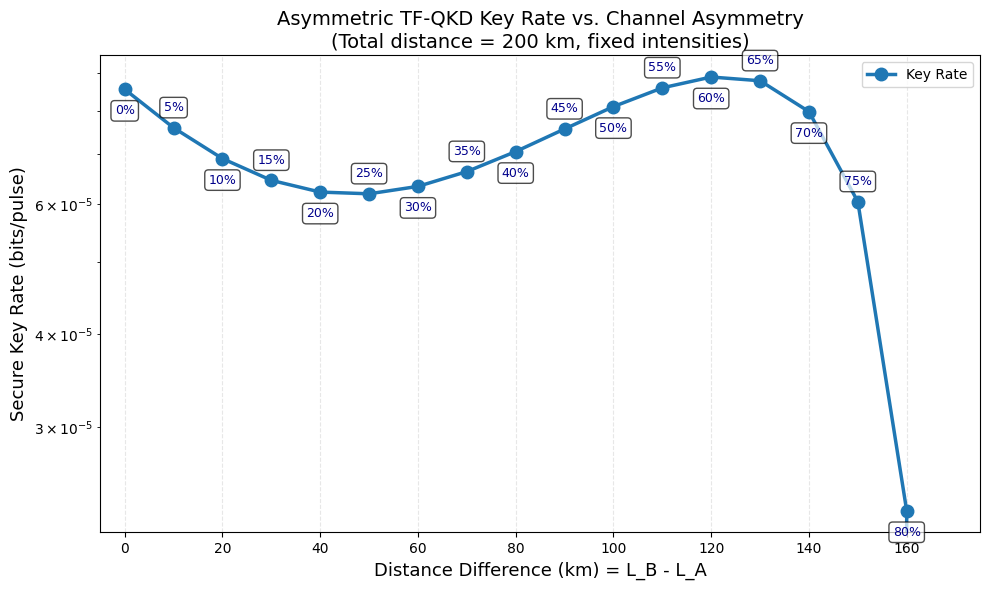

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

total = 200.00    # total distance

# Loop over different asymmetry levels

percentages = [95, 90, 85,80, 75, 70, 65, 60, 55, 50, 45, 40, 35, 30, 25, 20, 15, 10, 5, 0]
# percentages = [50, 45, 40, 35, 30, 25, 20, 15, 10, 5, 0]

results = []
print("Diff (%) | Diff (km) | L_A (km) | L_B (km) | Key rate (bits/pulse)")
print("-----------------------------------------------------------------")

for pct in percentages:
    diff = total * (pct / 100.0)
    L_A = (total - diff) / 2.0
    L_B = total - L_A
    R, _ = key_rate_asymmetric(
        L_A, L_B,
        mu_y_A, mu_y_B,
        p_y_A, p_y_B,
        mu_z_A, mu_z_B,
        p_z_A, p_z_B,
        mu_x=mu_x, p_x=p_x,
        p_v_A=p_v_A, p_v_B=p_v_B,
        N=N, alpha=alpha, Y0=Y0, ed=ed,
        f=f, epsilon=epsilon,
        E_Z_before=E_Z_before, E_Z_after=E_Z_after
    )
    results.append((pct, L_A, L_B, diff, R))
    print(f"{pct:8.0f}% | {diff:9.1f} | {L_A:8.1f} | {L_B:8.1f} | {R:.8e}")


# Plot with data labels

diffs = [r[3] for r in results]
rates = [r[4] for r in results]
labels = [f"{r[0]}%" for r in results]

plt.figure(figsize=(10, 6))
plt.plot(diffs, rates, 'o-', color='#1f77b4', linewidth=2.5, markersize=9, label='Key Rate')

# Add data labels
for i, (diff, rate, label) in enumerate(zip(diffs, rates, labels)):
    plt.annotate(label, (diff, rate),
                 textcoords="offset points",
                 xytext=(0, 12 if i % 2 == 0 else -18),
                 ha='center',
                 fontsize=9,
                 color='darkblue',
                 bbox=dict(boxstyle="round,pad=0.3", facecolor='white', alpha=0.7))

plt.xlabel('Distance Difference (km) = L_B - L_A', fontsize=13)
plt.ylabel('Secure Key Rate (bits/pulse)', fontsize=13)
plt.title('Asymmetric TF‑QKD Key Rate vs. Channel Asymmetry\n(Total distance = 200 km, fixed intensities)', fontsize=14)
plt.grid(True, alpha=0.3, linestyle='--')
plt.yscale('log')
plt.xlim(-5, 175)
plt.legend()
plt.tight_layout()
plt.show()

Below are 6 examples of various variations of symmetric/asymmetric distances and channels, for reference. This is only to give an idea of the variation of key rates for different scenarios.

All of the cases demonstrate the idea that the maximum key rate need not be obtained with symmetric channels or symmetric distances, and that the maximum key rate is obtained at different points, depending on the channels parameters and chosen distance asymmetry.


Configuration: Config 1 (default asymmetric)
mu_y_A=0.35, mu_y_B=0.50, mu_z_A=0.50, mu_z_B=0.65, mu_x=0.20
p_y_A=0.04, p_y_B=0.06, p_z_A=0.16, p_z_B=0.24, p_x=0.05

Diff (%) | L_A (km) | L_B (km) | Key rate (bits/pulse)
-----------------------------------------------------------------
      95% |      5.0 |    195.0 | 0.000000e+00
      90% |     10.0 |    190.0 | 0.000000e+00
      85% |     15.0 |    185.0 | 0.000000e+00
      80% |     20.0 |    180.0 | 2.311746e-05
      75% |     25.0 |    175.0 | 6.040443e-05
      70% |     30.0 |    170.0 | 7.989727e-05
      65% |     35.0 |    165.0 | 8.793652e-05
      60% |     40.0 |    160.0 | 8.896257e-05
      55% |     45.0 |    155.0 | 8.601809e-05
      50% |     50.0 |    150.0 | 8.114813e-05
      45% |     55.0 |    145.0 | 7.570407e-05
      40% |     60.0 |    140.0 | 7.056805e-05
      35% |     65.0 |    135.0 | 6.631546e-05
      30% |     70.0 |    130.0 | 6.333126e-05
      25% |     75.0 |    125.0 | 6.189211e-05
      20

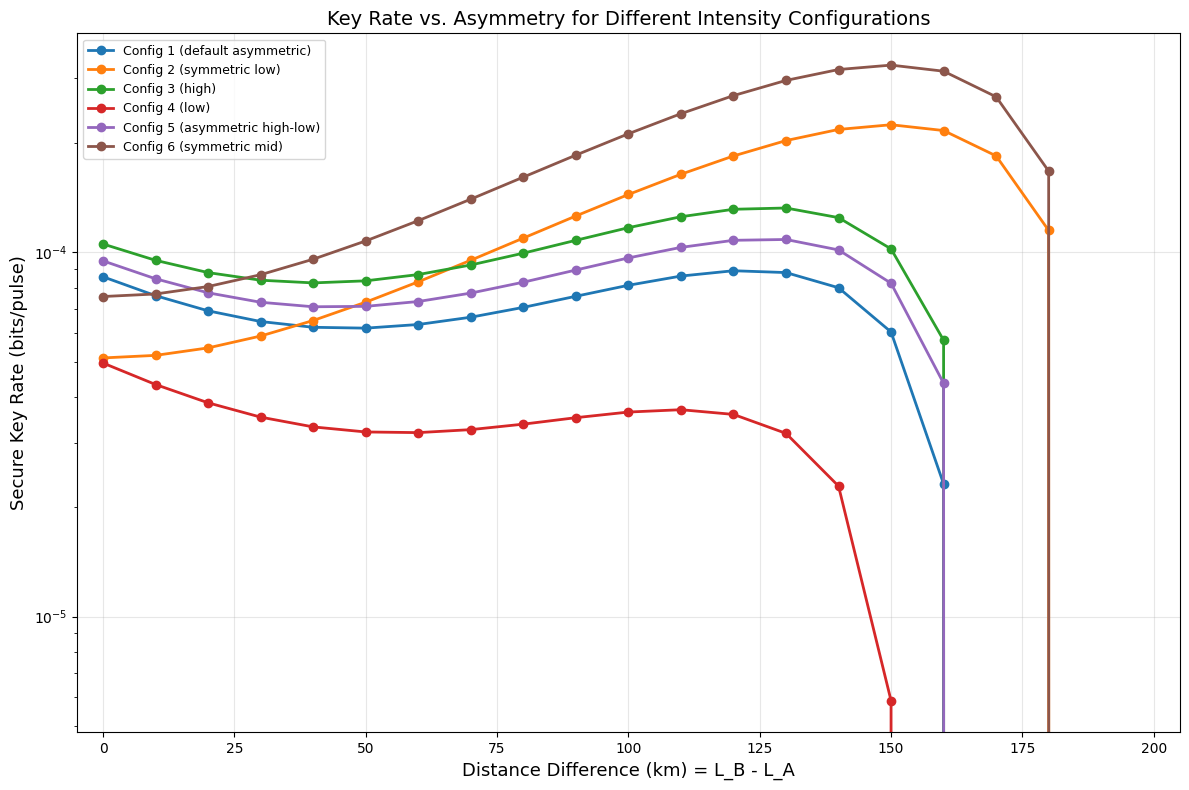

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 2. Define intensity configurations
# ------------------------------------------------------------
configs = [
    {
        'label': 'Config 1 (default asymmetric)',
        'mu_y_A': 0.35, 'mu_y_B': 0.50,
        'mu_z_A': 0.50, 'mu_z_B': 0.65,
        'mu_x': 0.20,
        'p_y_A': 0.04, 'p_y_B': 0.06,
        'p_z_A': 0.16, 'p_z_B': 0.24,
        'p_x': 0.05
    },
    {
        'label': 'Config 2 (symmetric low)',
        'mu_y_A': 0.30, 'mu_y_B': 0.30,
        'mu_z_A': 0.45, 'mu_z_B': 0.45,
        'mu_x': 0.15,
        'p_y_A': 0.04, 'p_y_B': 0.04,
        'p_z_A': 0.16, 'p_z_B': 0.16,
        'p_x': 0.05
    },
    {
        'label': 'Config 3 (high)',
        'mu_y_A': 0.50, 'mu_y_B': 0.60,
        'mu_z_A': 0.65, 'mu_z_B': 0.75,
        'mu_x': 0.25,
        'p_y_A': 0.04, 'p_y_B': 0.06,
        'p_z_A': 0.16, 'p_z_B': 0.24,
        'p_x': 0.05
    },
    {
        'label': 'Config 4 (low)',
        'mu_y_A': 0.20, 'mu_y_B': 0.30,
        'mu_z_A': 0.35, 'mu_z_B': 0.45,
        'mu_x': 0.10,
        'p_y_A': 0.04, 'p_y_B': 0.06,
        'p_z_A': 0.16, 'p_z_B': 0.24,
        'p_x': 0.05
    },
    {
        'label': 'Config 5 (asymmetric high-low)',
        'mu_y_A': 0.40, 'mu_y_B': 0.55,
        'mu_z_A': 0.55, 'mu_z_B': 0.70,
        'mu_x': 0.20,
        'p_y_A': 0.04, 'p_y_B': 0.06,
        'p_z_A': 0.16, 'p_z_B': 0.24,
        'p_x': 0.05
    },
    {
        'label': 'Config 6 (symmetric mid)',
        'mu_y_A': 0.40, 'mu_y_B': 0.40,
        'mu_z_A': 0.55, 'mu_z_B': 0.55,
        'mu_x': 0.15,
        'p_y_A': 0.05, 'p_y_B': 0.05,
        'p_z_A': 0.20, 'p_z_B': 0.20,
        'p_x': 0.05
    }
]

# 3. Fixed system parameters and distance splits

total = 200.0

# Distance percentage differences (asymmetry levels)
percentages = [95, 90, 85, 80, 75, 70, 65, 60, 55, 50, 45, 40, 35, 30, 25, 20, 15, 10, 5, 0]

# ------------------------------------------------------------
# 4. Loop over configurations and distance splits, print tables
# ------------------------------------------------------------
for cfg in configs:
    print("\n" + "="*80)
    print(f"Configuration: {cfg['label']}")
    print("="*80)
    print(f"mu_y_A={cfg['mu_y_A']:.2f}, mu_y_B={cfg['mu_y_B']:.2f}, "
          f"mu_z_A={cfg['mu_z_A']:.2f}, mu_z_B={cfg['mu_z_B']:.2f}, mu_x={cfg['mu_x']:.2f}")
    print(f"p_y_A={cfg['p_y_A']:.2f}, p_y_B={cfg['p_y_B']:.2f}, "
          f"p_z_A={cfg['p_z_A']:.2f}, p_z_B={cfg['p_z_B']:.2f}, p_x={cfg['p_x']:.2f}")
    print("\nDiff (%) | L_A (km) | L_B (km) | Key rate (bits/pulse)")
    print("-----------------------------------------------------------------")
    for pct in percentages:
        diff = total * (pct / 100.0)
        L_A = (total - diff) / 2.0
        L_B = total - L_A
        # Call function and handle cases where it returns (R, details) or just R
        res = key_rate_asymmetric(
            L_A=L_A, L_B=L_B,
            mu_y_A=cfg['mu_y_A'], mu_y_B=cfg['mu_y_B'],
            p_y_A=cfg['p_y_A'], p_y_B=cfg['p_y_B'],
            mu_z_A=cfg['mu_z_A'], mu_z_B=cfg['mu_z_B'],
            p_z_A=cfg['p_z_A'], p_z_B=cfg['p_z_B'],
            mu_x=cfg['mu_x'],
            p_x=cfg['p_x'],
            p_v_A=None, p_v_B=None,
            N=N, alpha=alpha, Y0=Y0, ed=ed,
            f=f, epsilon=epsilon,
            E_Z_before=E_Z_before, E_Z_after=E_Z_after
        )
        R = res[0] if isinstance(res, (tuple, list)) else res
        print(f"{pct:8.0f}% | {L_A:8.1f} | {L_B:8.1f} | {R:.6e}")

# ------------------------------------------------------------
# 5. Optional: plot all curves on one graph for comparison
# ------------------------------------------------------------
plt.figure(figsize=(12, 8))
for cfg in configs:
    rates = []
    diffs = []
    for pct in percentages:
        diff = total * (pct / 100.0)
        L_A = (total - diff) / 2.0
        L_B = total - L_A
        res = key_rate_asymmetric(
            L_A=L_A, L_B=L_B,
            mu_y_A=cfg['mu_y_A'], mu_y_B=cfg['mu_y_B'],
            p_y_A=cfg['p_y_A'], p_y_B=cfg['p_y_B'],
            mu_z_A=cfg['mu_z_A'], mu_z_B=cfg['mu_z_B'],
            p_z_A=cfg['p_z_A'], p_z_B=cfg['p_z_B'],
            mu_x=cfg['mu_x'],
            p_x=cfg['p_x'],
            p_v_A=None, p_v_B=None,
            N=N, alpha=alpha, Y0=Y0, ed=ed,
            f=f, epsilon=epsilon,
            E_Z_before=E_Z_before, E_Z_after=E_Z_after
        )
        R = res[0] if isinstance(res, (tuple, list)) else res
        diffs.append(diff)
        rates.append(R)
    plt.plot(diffs, rates, 'o-', label=cfg['label'], linewidth=2, markersize=6)

plt.xlabel('Distance Difference (km) = L_B - L_A', fontsize=13)
plt.ylabel('Secure Key Rate (bits/pulse)', fontsize=13)
plt.title('Key Rate vs. Asymmetry for Different Intensity Configurations', fontsize=14)
plt.grid(True, alpha=0.3)
plt.yscale('log')
plt.xlim(-5, 205)
plt.legend(loc='best', fontsize=9)
plt.tight_layout()
plt.show()

A bar graph to summarize the abpve results is given below:

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Assume key_rate_asymmetric and helpers are defined.
#    (They are the same as in the previous codes.)
# ------------------------------------------------------------

# ------------------------------------------------------------
# 2. Fixed distances
# ------------------------------------------------------------
L_A = 120.0
L_B = 80.0
print(f"Fixed distances: L_A = {L_A} km, L_B = {L_B} km")

# ------------------------------------------------------------
# 3. Define configurations
# ------------------------------------------------------------
configs = [
    {
        'label': 'Config 1 (default asym)',
        'mu_y_A': 0.35, 'mu_y_B': 0.50,
        'mu_z_A': 0.50, 'mu_z_B': 0.65,
        'mu_x': 0.20,
        'p_y_A': 0.04, 'p_y_B': 0.06,
        'p_z_A': 0.16, 'p_z_B': 0.24,
        'p_x': 0.05
    },
    {
        'label': 'Config 2 (sym low)',
        'mu_y_A': 0.30, 'mu_y_B': 0.30,
        'mu_z_A': 0.45, 'mu_z_B': 0.45,
        'mu_x': 0.15,
        'p_y_A': 0.04, 'p_y_B': 0.04,
        'p_z_A': 0.16, 'p_z_B': 0.16,
        'p_x': 0.05
    },
    {
        'label': 'Config 3 (high)',
        'mu_y_A': 0.50, 'mu_y_B': 0.60,
        'mu_z_A': 0.65, 'mu_z_B': 0.75,
        'mu_x': 0.25,
        'p_y_A': 0.04, 'p_y_B': 0.06,
        'p_z_A': 0.16, 'p_z_B': 0.24,
        'p_x': 0.05
    },
    {
        'label': 'Config 4 (low)',
        'mu_y_A': 0.20, 'mu_y_B': 0.30,
        'mu_z_A': 0.35, 'mu_z_B': 0.45,
        'mu_x': 0.10,
        'p_y_A': 0.04, 'p_y_B': 0.06,
        'p_z_A': 0.16, 'p_z_B': 0.24,
        'p_x': 0.05
    },
    {
        'label': 'Config 5 (asym high-low)',
        'mu_y_A': 0.40, 'mu_y_B': 0.55,
        'mu_z_A': 0.55, 'mu_z_B': 0.70,
        'mu_x': 0.20,
        'p_y_A': 0.04, 'p_y_B': 0.06,
        'p_z_A': 0.16, 'p_z_B': 0.24,
        'p_x': 0.05
    },
    {
        'label': 'Config 6 (sym mid)',
        'mu_y_A': 0.40, 'mu_y_B': 0.40,
        'mu_z_A': 0.55, 'mu_z_B': 0.55,
        'mu_x': 0.15,
        'p_y_A': 0.05, 'p_y_B': 0.05,
        'p_z_A': 0.20, 'p_z_B': 0.20,
        'p_x': 0.05
    }
]

# ------------------------------------------------------------
# 4. Compute key rates
# ------------------------------------------------------------
rates = []
labels = []
for cfg in configs:
    R = key_rate_asymmetric(
        L_A, L_B,
        mu_x_A=cfg['mu_x'], mu_x_B=cfg['mu_x'],
        mu_y_A=cfg['mu_y_A'], mu_y_B=cfg['mu_y_B'],
        p_y_A=cfg['p_y_A'], p_y_B=cfg['p_y_B'],
        mu_z_A=cfg['mu_z_A'], mu_z_B=cfg['mu_z_B'],
        p_z_A=cfg['p_z_A'], p_z_B=cfg['p_z_B'],
        p_x=cfg['p_x'],
        p_v_A=None, p_v_B=None,
        N=1e13, alpha=0.165, Y0=1e-8, ed=0.03,
        f=1.16, epsilon=1e-10,
        E_Z_before=0.25, E_Z_after=0.003
    )
    rates.append(R)
    labels.append(cfg['label'])
    print(f"{cfg['label']}: {R:.6e}")

# ------------------------------------------------------------
# 5. Plot
# ------------------------------------------------------------
plt.figure(figsize=(10, 6))
bars = plt.bar(labels, rates, color='skyblue', edgecolor='black')
plt.yscale('log')   # because rates span orders of magnitude
plt.ylabel('Secure Key Rate (bits/pulse)')
plt.title(f'Key rates for different configurations (L_A={L_A}, L_B={L_B})')
plt.xticks(rotation=15, ha='right')
plt.grid(axis='y', alpha=0.3)

# Add value labels on top of bars
for bar, rate in zip(bars, rates):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
             f'{rate:.2e}', ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

Fixed distances: L_A = 120.0 km, L_B = 80.0 km


TypeError: key_rate_asymmetric() got an unexpected keyword argument 'mu_x_A'. Did you mean 'mu_y_A'?

# Symmetric and asymmetric intensity channels

Here we show how selection of symmetric/asymmetric channels (intensities and probabilites) can affect the overall key rate - depending on selection of channel parameters, either asymmetric or symmetric channels can give better key rates.

While we show ahead that the best key rates are generally obtained with asymmetric channels and asymmetric distances, in this section we show that manipulation of the channels can yield different results, as per requirements.

## Testing: 1. Symmetric channels beat asymmetric channels

This cell gives an example of selection of channel parameters which show that symmetric channels CAN beat asymmetric channels, for variation in distance asymmetry, if required:

Configuration: Same intensities at Alice and Bob
mu_y_A = 0.35, mu_y_B = 0.35, mu_z_A = 0.50, mu_z_B = 0.50, mu_x = 0.20
p_y_A = 0.05, p_y_B = 0.05, p_z_A = 0.20, p_z_B = 0.20, p_x = 0.05

Diff (%) | L_A (km) | L_B (km) | Key rate (bits/pulse)
-------------------------------------------------------------
       0% |    100.0 |    100.0 | 6.508993e-05
       1% |     99.0 |    101.0 | 6.513184e-05
       2% |     98.0 |    102.0 | 6.525758e-05
       3% |     97.0 |    103.0 | 6.546726e-05
       4% |     96.0 |    104.0 | 6.576104e-05
       5% |     95.0 |    105.0 | 6.613914e-05
       6% |     94.0 |    106.0 | 6.660186e-05
       7% |     93.0 |    107.0 | 6.714955e-05
       8% |     92.0 |    108.0 | 6.778262e-05
       9% |     91.0 |    109.0 | 6.850154e-05
      10% |     90.0 |    110.0 | 6.930685e-05
      11% |     89.0 |    111.0 | 7.019913e-05
      12% |     88.0 |    112.0 | 7.117902e-05
      13% |     87.0 |    113.0 | 7.224721e-05
      14% |     86.0 |    114.0 | 7.

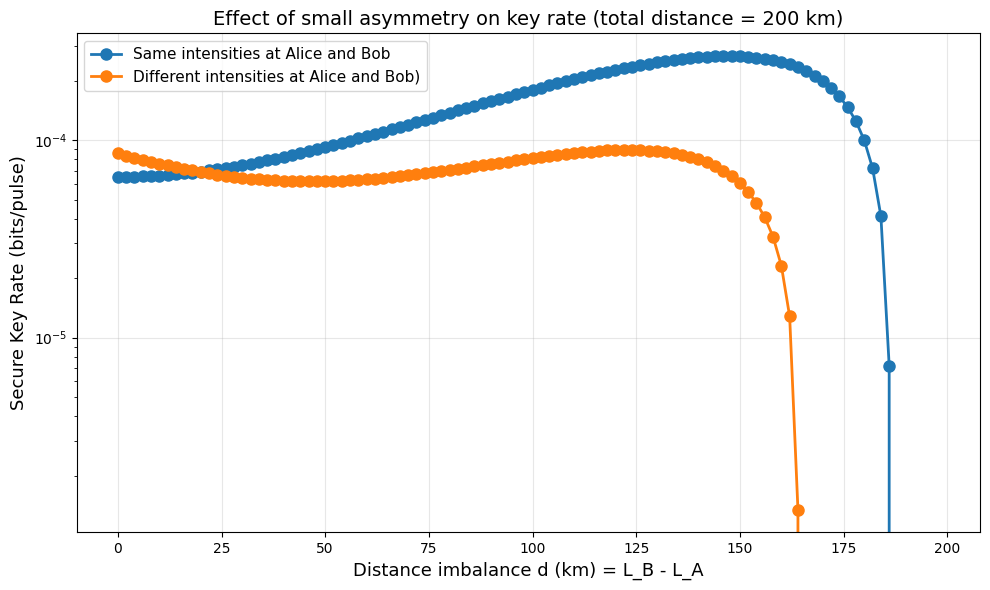

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd


# 2. Fixed parameters (system-wide)
# ------------------------------------------------------------

p_v_A = None
p_v_B = None

# System-wide fixed parameters (copied from cell 0O_FAdfbT5Of example)
N = 1e13
alpha = 0.165
Y0 = 1e-8
ed = 0.03
f = 1.16
epsilon = 1e-10
E_Z_before = 0.25
E_Z_after = 0.003
p_x = 0.05 # Weak decoy probability

# ------------------------------------------------------------
# 3. Define the two configurations
# ------------------------------------------------------------
# ---- Symmetric configuration (from Config 6) ----
sym_config = {
    'label': 'Same intensities at Alice and Bob',
    'mu_x': 0.20,
    'mu_y_A': 0.35, 'mu_y_B': 0.35,
    'p_y_A': 0.05, 'p_y_B': 0.05,
    'mu_z_A': 0.50, 'mu_z_B': 0.50,
    'p_z_A': 0.20, 'p_z_B': 0.20
}

# ---- Asymmetric configuration (from Config 1) ----
asym_config = {
    'label': 'Different intensities at Alice and Bob)',
    'mu_x': 0.20,
    'mu_y_A': 0.35, 'mu_y_B': 0.50,
    'p_y_A': 0.04, 'p_y_B': 0.06,
    'mu_z_A': 0.50, 'mu_z_B': 0.65,
    'p_z_A': 0.16, 'p_z_B': 0.24
}

# ------------------------------------------------------------
# 4. Sweep asymmetry levels
# ------------------------------------------------------------
total = 200.0
# percentages from 0% to 10% in steps of 1% (small asymmetry)
percentages = np.arange(0, 100, 1)   # 0,1,2,...,10
diffs_km = total * (percentages / 100.0)

results = []

for cfg in [sym_config, asym_config]:
    label = cfg['label']
    mu_x = cfg['mu_x']
    mu_y_A = cfg['mu_y_A']; mu_y_B = cfg['mu_y_B']
    p_y_A = cfg['p_y_A']; p_y_B = cfg['p_y_B']
    mu_z_A = cfg['mu_z_A']; mu_z_B = cfg['mu_z_B']
    p_z_A = cfg['p_z_A']; p_z_B = cfg['p_z_B']

    rates = []
    for pct, diff in zip(percentages, diffs_km):
        L_A = (total - diff) / 2.0
        L_B = total - L_A
        R_value, _ = key_rate_asymmetric(
            L_A=L_A, L_B=L_B,
            mu_y_A=mu_y_A, mu_y_B=mu_y_B,
            p_y_A=p_y_A, p_y_B=p_y_B,
            mu_z_A=mu_z_A, mu_z_B=mu_z_B,
            p_z_A=p_z_A, p_z_B=p_z_B,
            mu_x=mu_x,
            p_x=p_x,
            p_v_A=p_v_A, p_v_B=p_v_B,
            N=N, alpha=alpha, Y0=Y0, ed=ed,
            f=f, epsilon=epsilon,
            E_Z_before=E_Z_before, E_Z_after=E_Z_after
        )
        rates.append(R_value)

    results.append({
        'label': label,
        'percentages': percentages,
        'diffs_km': diffs_km,
        'rates': rates,
        'params': cfg
    })

# ------------------------------------------------------------
# 5. Print tables
# ------------------------------------------------------------
for res in results:
    cfg = res['params']
    print("="*80)
    print(f"Configuration: {res['label']}")
    print("="*80)
    print(f"mu_y_A = {cfg['mu_y_A']:.2f}, mu_y_B = {cfg['mu_y_B']:.2f}, "
          f"mu_z_A = {cfg['mu_z_A']:.2f}, mu_z_B = {cfg['mu_z_B']:.2f}, mu_x = {cfg['mu_x']:.2f}")
    print(f"p_y_A = {cfg['p_y_A']:.2f}, p_y_B = {cfg['p_y_B']:.2f}, "
          f"p_z_A = {cfg['p_z_A']:.2f}, p_z_B = {cfg['p_z_B']:.2f}, p_x = {p_x:.2f}")
    print("\nDiff (%) | L_A (km) | L_B (km) | Key rate (bits/pulse)")
    print("-------------------------------------------------------------")
    for pct, L_A, L_B, R_value in zip(res['percentages'], # Changed R to R_value
                                 [(total - d)/2.0 for d in res['diffs_km']],
                                 [(total + d)/2.0 for d in res['diffs_km']],
                                 res['rates']):
        print(f"{pct:8.0f}% | {L_A:8.1f} | {L_B:8.1f} | {R_value:.6e}") # Changed R to R_value
    print("\n")

# ------------------------------------------------------------
# 6. Plot both curves on one graph
# ------------------------------------------------------------
plt.figure(figsize=(10,6))
for res in results:
    plt.plot(res['diffs_km'], res['rates'], 'o-', label=res['label'], linewidth=2, markersize=8)

plt.xlabel('Distance imbalance d (km) = L_B - L_A', fontsize=13)
plt.ylabel('Secure Key Rate (bits/pulse)', fontsize=13)
plt.title('Effect of small asymmetry on key rate (total distance = 200 km)', fontsize=14)
plt.grid(True, alpha=0.3)
plt.yscale('log')
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()

The below cell expands on the results of the cell above, and analyses the accepted deviation of the key rate (from the base case of no distance asymmetry) with the change in the distance asymmetry [1%, 5%, 10% etc.]

For this example, there is a small area where the asymmetric channels hold an advatangein key rate compared to the symmetric channel, but that advantage is quickly lost as distance asymmetry increases. The next example shows a reverse case.

Part 1: Maximum permissible distance asymmetry for given key‑rate drops
(Two‑sided tolerance: rate must stay within ±Δ% of R0)

Symmetric configuration (R0 = 6.5090e-05)
Drop   | Max Diff (km) | Max Diff (%) | L_A (km) | L_B (km) | Rate at limit (target)
----------------------------------------------------------------------------------------
  0.0%  |        0.000 |        0.000 | 100.00000 | 100.00000 |     6.5090e-05
  0.1%  |        2.443 |        1.221 | 98.77870 | 101.22130 |     6.5155e-05
  1.0%  |        7.872 |        3.936 | 96.06418 | 103.93582 |     6.5741e-05
  2.0%  |       11.132 |        5.566 | 94.43423 | 105.56577 |     6.6392e-05
  2.5%  |       12.438 |        6.219 | 93.78093 | 106.21907 |     6.6717e-05
  3.0%  |       13.624 |        6.812 | 93.18792 | 106.81208 |     6.7043e-05
  4.0%  |       15.728 |        7.864 | 92.13613 | 107.86387 |     6.7694e-05
  5.0%  |       17.576 |        8.788 | 91.21219 | 108.78781 |     6.8344e-05
 10.0%  |       24.803 |       

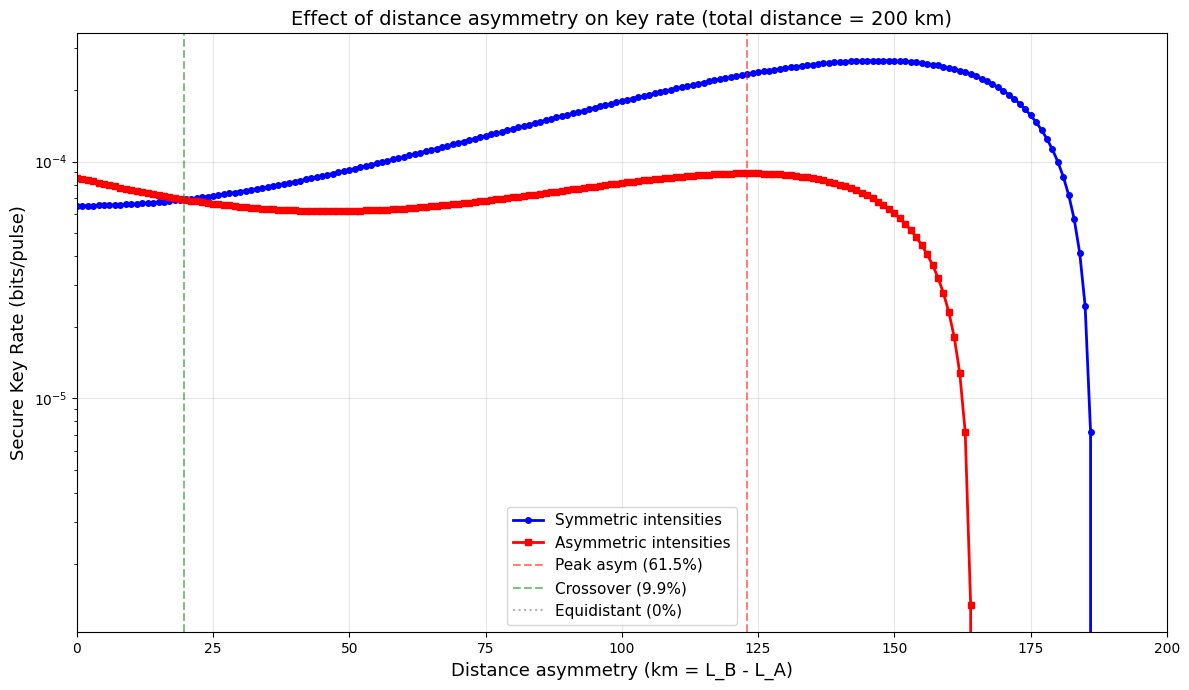

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize_scalar


# System-wide fixed parameters (copied from cell 0O_FAdfbT5Of example)
N = 1e13
alpha = 0.165
Y0 = 1e-8
ed = 0.03
f = 1.16
epsilon = 1e-10
E_Z_before = 0.25
E_Z_after = 0.003
p_x = 0.05 # Weak decoy probability

p_v_A = None # Initialized for `key_rate_asymmetric` call
p_v_B = None # Initialized for `key_rate_asymmetric` call

# Symmetric: Config 6
sym_config = {
    'label': 'Symmetric intensities',
    'mu_x': 0.20,
    'mu_y_A': 0.35, 'mu_y_B': 0.35,
    'p_y_A': 0.05, 'p_y_B': 0.05,
    'mu_z_A': 0.50, 'mu_z_B': 0.50,
    'p_z_A': 0.20, 'p_z_B': 0.20
}

# Asymmetric: Config 1
asym_config = {
    'label': 'Asymmetric intensities',
    'mu_x': 0.20,
    'mu_y_A': 0.35, 'mu_y_B': 0.50,
    'p_y_A': 0.04, 'p_y_B': 0.06,
    'mu_z_A': 0.50, 'mu_z_B': 0.65,
    'p_z_A': 0.16, 'p_z_B': 0.24
}

# ------------------------------------------------------------
# 4. Sweep asymmetry from 0% to 100% in steps of 0.5% for accuracy
# ------------------------------------------------------------
total = 200.0
percent = np.linspace(0, 100, 201)   # 0 to 60 in 0.5% steps
diffs_km = total * (percent / 100.0)

# Storage
rates = {'Symmetric': [], 'Asymmetric': []}
for cfg, rates_list in zip([sym_config, asym_config], [rates['Symmetric'], rates['Asymmetric']]):
    mu_x = cfg['mu_x']
    mu_y_A = cfg['mu_y_A']; mu_y_B = cfg['mu_y_B']
    p_y_A = cfg['p_y_A']; p_y_B = cfg['p_y_B']
    mu_z_A = cfg['mu_z_A']; mu_z_B = cfg['mu_z_B']
    p_z_A = cfg['p_z_A']; p_z_B = cfg['p_z_B']

    for diff in diffs_km:
        L_A = (total - diff) / 2.0
        L_B = total - L_A
        R_value, _ = key_rate_asymmetric( # Unpack the tuple
            L_A=L_A, L_B=L_B, # Using keyword arguments for clarity and correctness
            mu_x=mu_x,
            mu_y_A=mu_y_A, mu_y_B=mu_y_B,
            p_y_A=p_y_A, p_y_B=p_y_B,
            mu_z_A=mu_z_A, mu_z_B=mu_z_B,
            p_z_A=p_z_A, p_z_B=p_z_B,
            p_x=p_x,
            p_v_A=p_v_A, p_v_B=p_v_B,
            N=N, alpha=alpha, Y0=Y0, ed=ed,
            f=f, epsilon=epsilon,
            E_Z_before=E_Z_before, E_Z_after=E_Z_after
        )
        rates_list.append(R_value) # Append only the numerical key rate

# Convert to numpy arrays
R_sym = np.array(rates['Symmetric'])
R_asym = np.array(rates['Asymmetric'])

# ------------------------------------------------------------
# 5. Part 1: Allowed asymmetry for given key‑rate drops
# ------------------------------------------------------------
# Equidistant key rates (at diff=0)
R0_sym = R_sym[0]
R0_asym = R_asym[0]

# ------------------------------------------------------------
# Part 1 – Maximum permissible asymmetry (two‑sided tolerance)
# ------------------------------------------------------------
drop_values = [0.00, 0.001, 0.01, 0.02, 0.025, 0.03, 0.04, 0.05, 0.10]   # 0%, 0.1%, 1%, 2%, 5%, 10%

def find_first_boundary_crossing(R_rates, R0, drop, diffs, rates_full):
    lower = R0 * (1 - drop)
    upper = R0 * (1 + drop)
    if R_rates[0] < lower or R_rates[0] > upper:
        return 0.0, R_rates[0]
    for i in range(1, len(R_rates)):
        if R_rates[i] < lower or R_rates[i] > upper:
            x1, y1 = diffs[i-1], R_rates[i-1]
            x2, y2 = diffs[i], R_rates[i]
            if y2 == y1:
                x_cross = x1
            else:
                if R_rates[i] > upper:
                    x_cross = x1 + (upper - y1) * (x2 - x1) / (y2 - y1)
                else:
                    x_cross = x1 + (lower - y1) * (x2 - x1) / (y2 - y1)
            x_cross = max(0.0, min(diffs[-1], x_cross))
            # Return the boundary value (target) as the rate at limit
            return x_cross, (upper if R_rates[i] > upper else lower)
    return diffs[-1], R_rates[-1]

print("="*80)
print("Part 1: Maximum permissible distance asymmetry for given key‑rate drops")
print("(Two‑sided tolerance: rate must stay within ±Δ% of R0)")
print("="*80)

print("\nSymmetric configuration (R0 = {:.4e})".format(R0_sym))
print("Drop   | Max Diff (km) | Max Diff (%) | L_A (km) | L_B (km) | Rate at limit (target)")
print("----------------------------------------------------------------------------------------")
for drop in drop_values:
    max_diff, rate_at = find_first_boundary_crossing(R_sym, R0_sym, drop, diffs_km, R_sym)
    L_A = (total - max_diff) / 2.0
    L_B = total - L_A
    pct = max_diff / total * 100
    drop_pct = drop * 100
    print("{:5.1f}%  | {:12.3f} | {:12.3f} | {:8.5f} | {:8.5f} | {:14.4e}".format(
        drop_pct, max_diff, pct, L_A, L_B, rate_at))

print("\nAsymmetric configuration (R0 = {:.4e})".format(R0_asym))
print("Drop   | Max Diff (km) | Max Diff (%) | L_A (km) | L_B (km) | Rate at limit (target)")
print("----------------------------------------------------------------------------------------")
for drop in drop_values:
    max_diff, rate_at = find_first_boundary_crossing(R_asym, R0_asym, drop, diffs_km, R_asym)
    L_A = (total - max_diff) / 2.0
    L_B = total - L_A
    pct = max_diff / total * 100
    drop_pct = drop * 100
    print("{:5.1f}%  | {:12.3f} | {:12.3f} | {:8.5f} | {:8.5f} | {:14.4e}".format(
        drop_pct, max_diff, pct, L_A, L_B, rate_at))


# ------------------------------------------------------------
# 6. Part 2 & 3: Crossover point
# ------------------------------------------------------------
# Find where R_asym crosses R_sym (i.e., R_asym - R_sym < 0)
diff_R = R_asym - R_sym
# Find first index where diff_R < 0 (i.e., asymmetric becomes worse)
neg_idx = np.where(diff_R < 0)[0]
if len(neg_idx) > 0:
    # Linear interpolation to get precise crossover
    i = neg_idx[0]
    if i > 0:
        x1, y1 = diffs_km[i-1], diff_R[i-1]
        x2, y2 = diffs_km[i], diff_R[i]
        x_cross = x1 - y1 * (x2 - x1) / (y2 - y1)
        pct_cross = x_cross / total * 100
        L_A_cross = (total - x_cross)/2.0
        L_B_cross = total - L_A_cross
        print("\n"+"="*80)
        print("Part 2 & 3: Crossover point")
        print("="*80)
        print("Asymmetric configuration becomes worse than symmetric at:")
        print("  Diff = {:.2f} km  ({:.2f}%)".format(x_cross, pct_cross))
        print("  L_A = {:.2f} km, L_B = {:.2f} km".format(L_A_cross, L_B_cross))
    else:
        print("\nCrossover occurs at 0% asymmetry (asymmetric is always worse).")
else:
    print("\nNo crossover within 0-60% asymmetry. Asymmetric remains better.")

# ------------------------------------------------------------
# 7. Part 4: Peak for asymmetric configuration
# ------------------------------------------------------------
# Find maximum key rate and its asymmetry
idx_peak = np.argmax(R_asym)
peak_diff = diffs_km[idx_peak]
peak_pct = peak_diff / total * 100
peak_R = R_asym[idx_peak]

print("\n"+"="*80)
print("Part 4: Peak key rate for asymmetric configuration")
print("="*80)
print("Peak key rate = {:.4e} bits/pulse".format(peak_R))
print("Occurs at Diff = {:.2f} km  ({:.2f}%)".format(peak_diff, peak_pct))
print("  L_A = {:.2f} km, L_B = {:.2f} km".format((total - peak_diff)/2.0, (total + peak_diff)/2.0))

# ------------------------------------------------------------
# 8. Plot
# ------------------------------------------------------------
plt.figure(figsize=(12, 7))
plt.plot(diffs_km, R_sym, 'o-', label='Symmetric intensities', linewidth=2, markersize=4, color='blue')
plt.plot(diffs_km, R_asym, 's-', label='Asymmetric intensities', linewidth=2, markersize=4, color='red')

# Mark the peak and crossover
plt.axvline(peak_diff, color='red', linestyle='--', alpha=0.5, label=f'Peak asym ({peak_pct:.1f}%)')
if len(neg_idx) > 0:
    plt.axvline(x_cross, color='green', linestyle='--', alpha=0.5, label=f'Crossover ({pct_cross:.1f}%)')

# Mark the equidistant point
plt.axvline(0, color='black', linestyle=':', alpha=0.3, label='Equidistant (0%)')

plt.xlabel('Distance asymmetry (km = L_B - L_A)', fontsize=13)
plt.ylabel('Secure Key Rate (bits/pulse)', fontsize=13)
plt.title('Effect of distance asymmetry on key rate (total distance = 200 km)', fontsize=14)
plt.grid(True, alpha=0.3)
plt.yscale('log')
plt.xlim(0, 200)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 9. Summary print (corrected)
# ------------------------------------------------------------

def get_max_diff_for_drop(R_rates, R0, drop, diffs, total):
    target = R0 * (1 - drop)
    mask = R_rates >= target
    if np.any(mask):
        idx = np.argmax(~mask) if np.any(~mask) else len(R_rates)-1
        if idx == 0:
            idx = len(R_rates)-1
        return diffs[idx]
    else:
        return 0.0

d1_sym = get_max_diff_for_drop(R_sym, R0_sym, 0.01, diffs_km, total)
d1_asym = get_max_diff_for_drop(R_asym, R0_asym, 0.01, diffs_km, total)



## Testing: 2. Asymmetric channels beat symmetric channels

Here we prove the opposite of the first test case: that asymmetric channels beat symmetric channels.

This is actually the general expected trend; the first case was just an exercise to demonstrate the eed for careful selection of channel parameters for distance asymmetry.

Part 1: Maximum permissible distance asymmetry for given key‑rate drops
(Two‑sided tolerance: rate must stay within ±Δ% of R0)

Symmetric configuration (R0 = 2.2783e-07)
Drop   | Max Diff (km) | Max Diff (%) | L_A (km) | L_B (km) | Rate at limit (target)
----------------------------------------------------------------------------------------
  0.0%  |        0.000 |        0.000 | 250.00000 | 250.00000 |     2.2783e-07
  0.1%  |        2.213 |        0.443 | 248.89356 | 251.10644 |     2.2805e-07
  1.0%  |        7.419 |        1.484 | 246.29041 | 253.70959 |     2.3010e-07
  2.0%  |       10.457 |        2.091 | 244.77145 | 255.22855 |     2.3238e-07
  2.5%  |       11.677 |        2.335 | 244.16135 | 255.83865 |     2.3352e-07
  3.0%  |       12.824 |        2.565 | 243.58800 | 256.41200 |     2.3466e-07
  4.0%  |       14.813 |        2.963 | 242.59338 | 257.40662 |     2.3694e-07
  5.0%  |       16.518 |        3.304 | 241.74083 | 258.25917 |     2.3922e-07
 10.0%  |       23.301 |

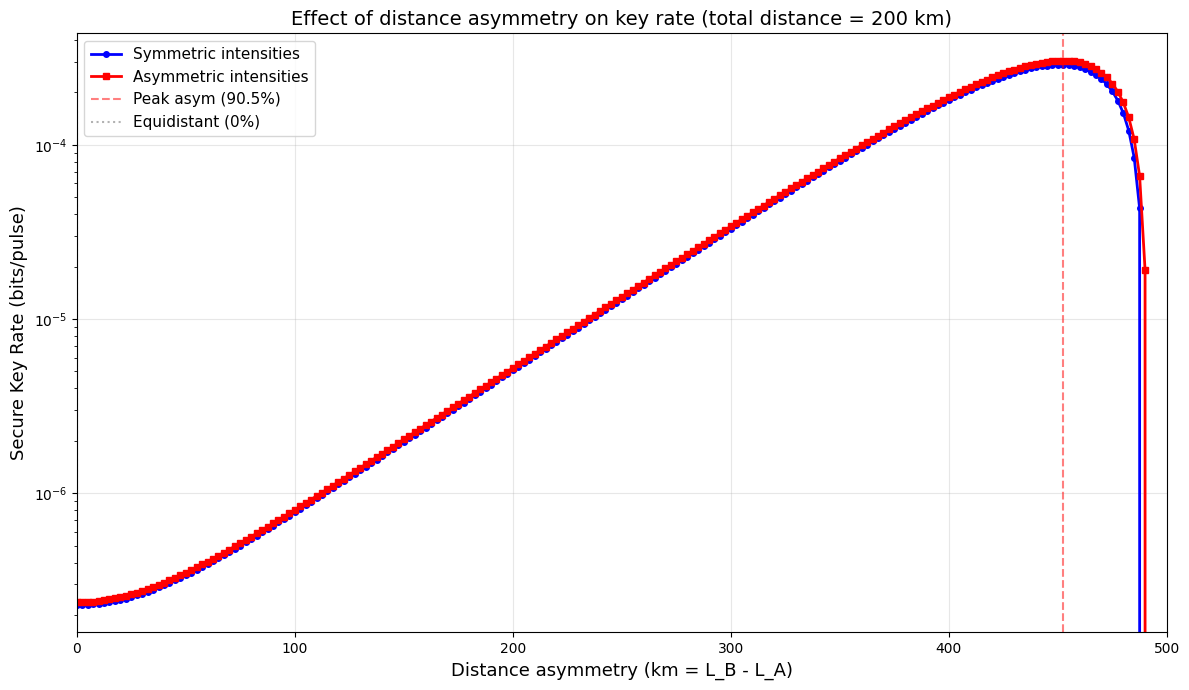

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize_scalar


# System-wide fixed parameters (copied from cell 0O_FAdfbT5Of example)
N = 1e13
alpha = 0.165
Y0 = 1e-8
ed = 0.03
f = 1.16
epsilon = 1e-10
E_Z_before = 0.25
E_Z_after = 0.003
p_x = 0.05 # Weak decoy probability

p_v_A = None # Initialized for `key_rate_asymmetric` call
p_v_B = None # Initialized for `key_rate_asymmetric` call

# Symmetric: Config 6
sym_config = {
    'label': 'Symmetric intensities',
    'mu_x': 0.100, 'p_x': 0.05,
    'mu_y_A': 0.387, 'mu_y_B': 0.387,
    'p_y_A': 0.044, 'p_y_B': 0.044,
    'mu_z_A': 0.470, 'mu_z_B': 0.470,
    'p_z_A': 0.20, 'p_z_B': 0.20
}

# Asymmetric: Config 1
asym_config = {
    'label': 'Asymmetric intensities',
    'mu_x': 0.100, 'p_x': 0.133,
    'mu_y_A': 0.342, 'mu_y_B': 0.345,
    'p_y_A': 0.05, 'p_y_B': 0.05,
    'mu_z_A': 0.463, 'mu_z_B': 0.459,
    'p_z_A': 0.2, 'p_z_B': 0.2
}


# ------------------------------------------------------------
# 4. Sweep asymmetry from 0% to 100% in steps of 0.5% for accuracy
# ------------------------------------------------------------
total = 500.0
percent = np.linspace(0, 100, 201)   # 0 to 60 in 0.5% steps
diffs_km = total * (percent / 100.0)

# Storage
rates = {'Symmetric': [], 'Asymmetric': []}
for cfg, rates_list in zip([sym_config, asym_config], [rates['Symmetric'], rates['Asymmetric']]):
    mu_x = cfg['mu_x']
    mu_y_A = cfg['mu_y_A']; mu_y_B = cfg['mu_y_B']
    p_y_A = cfg['p_y_A']; p_y_B = cfg['p_y_B']
    mu_z_A = cfg['mu_z_A']; mu_z_B = cfg['mu_z_B']
    p_z_A = cfg['p_z_A']; p_z_B = cfg['p_z_B']

    for diff in diffs_km:
        L_A = (total - diff) / 2.0
        L_B = total - L_A
        R_value, _ = key_rate_asymmetric( # Unpack the tuple
            L_A=L_A, L_B=L_B, # Using keyword arguments for clarity and correctness
            mu_x=mu_x,
            mu_y_A=mu_y_A, mu_y_B=mu_y_B,
            p_y_A=p_y_A, p_y_B=p_y_B,
            mu_z_A=mu_z_A, mu_z_B=mu_z_B,
            p_z_A=p_z_A, p_z_B=p_z_B,
            p_x=p_x,
            p_v_A=p_v_A, p_v_B=p_v_B,
            N=N, alpha=alpha, Y0=Y0, ed=ed,
            f=f, epsilon=epsilon,
            E_Z_before=E_Z_before, E_Z_after=E_Z_after
        )
        rates_list.append(R_value) # Append only the numerical key rate

# Convert to numpy arrays
R_sym = np.array(rates['Symmetric'])
R_asym = np.array(rates['Asymmetric'])

# ------------------------------------------------------------
# 5. Part 1: Allowed asymmetry for given key‑rate drops
# ------------------------------------------------------------
# Equidistant key rates (at diff=0)
R0_sym = R_sym[0]
R0_asym = R_asym[0]

# ------------------------------------------------------------
# Part 1 – Maximum permissible asymmetry (two‑sided tolerance)
# ------------------------------------------------------------
drop_values = [0.00, 0.001, 0.01, 0.02, 0.025, 0.03, 0.04, 0.05, 0.10]   # 0%, 0.1%, 1%, 2%, 5%, 10%

def find_first_boundary_crossing(R_rates, R0, drop, diffs, rates_full):
    lower = R0 * (1 - drop)
    upper = R0 * (1 + drop)
    if R_rates[0] < lower or R_rates[0] > upper:
        return 0.0, R_rates[0]
    for i in range(1, len(R_rates)):
        if R_rates[i] < lower or R_rates[i] > upper:
            x1, y1 = diffs[i-1], R_rates[i-1]
            x2, y2 = diffs[i], R_rates[i]
            if y2 == y1:
                x_cross = x1
            else:
                if R_rates[i] > upper:
                    x_cross = x1 + (upper - y1) * (x2 - x1) / (y2 - y1)
                else:
                    x_cross = x1 + (lower - y1) * (x2 - x1) / (y2 - y1)
            x_cross = max(0.0, min(diffs[-1], x_cross))
            # Return the boundary value (target) as the rate at limit
            return x_cross, (upper if R_rates[i] > upper else lower)
    return diffs[-1], R_rates[-1]

print("="*80)
print("Part 1: Maximum permissible distance asymmetry for given key‑rate drops")
print("(Two‑sided tolerance: rate must stay within ±Δ% of R0)")
print("="*80)

print("\nSymmetric configuration (R0 = {:.4e})".format(R0_sym))
print("Drop   | Max Diff (km) | Max Diff (%) | L_A (km) | L_B (km) | Rate at limit (target)")
print("----------------------------------------------------------------------------------------")
for drop in drop_values:
    max_diff, rate_at = find_first_boundary_crossing(R_sym, R0_sym, drop, diffs_km, R_sym)
    L_A = (total - max_diff) / 2.0
    L_B = total - L_A
    pct = max_diff / total * 100
    drop_pct = drop * 100
    print("{:5.1f}%  | {:12.3f} | {:12.3f} | {:8.5f} | {:8.5f} | {:14.4e}".format(
        drop_pct, max_diff, pct, L_A, L_B, rate_at))

print("\nAsymmetric configuration (R0 = {:.4e})".format(R0_asym))
print("Drop   | Max Diff (km) | Max Diff (%) | L_A (km) | L_B (km) | Rate at limit (target)")
print("----------------------------------------------------------------------------------------")
for drop in drop_values:
    max_diff, rate_at = find_first_boundary_crossing(R_asym, R0_asym, drop, diffs_km, R_asym)
    L_A = (total - max_diff) / 2.0
    L_B = total - L_A
    pct = max_diff / total * 100
    drop_pct = drop * 100
    print("{:5.1f}%  | {:12.3f} | {:12.3f} | {:8.5f} | {:8.5f} | {:14.4e}".format(
        drop_pct, max_diff, pct, L_A, L_B, rate_at))


# ------------------------------------------------------------
# 6. Part 2 & 3: Crossover point
# ------------------------------------------------------------
# Find where R_asym crosses R_sym (i.e., R_asym - R_sym < 0)
diff_R = R_asym - R_sym
# Find first index where diff_R < 0 (i.e., asymmetric becomes worse)
neg_idx = np.where(diff_R < 0)[0]
if len(neg_idx) > 0:
    # Linear interpolation to get precise crossover
    i = neg_idx[0]
    if i > 0:
        x1, y1 = diffs_km[i-1], diff_R[i-1]
        x2, y2 = diffs_km[i], diff_R[i]
        x_cross = x1 - y1 * (x2 - x1) / (y2 - y1)
        pct_cross = x_cross / total * 100
        L_A_cross = (total - x_cross)/2.0
        L_B_cross = total - L_A_cross
        print("\n"+"="*80)
        print("Part 2 & 3: Crossover point")
        print("="*80)
        print("Asymmetric configuration becomes worse than symmetric at:")
        print("  Diff = {:.2f} km  ({:.2f}%)".format(x_cross, pct_cross))
        print("  L_A = {:.2f} km, L_B = {:.2f} km".format(L_A_cross, L_B_cross))
    else:
        print("\nCrossover occurs at 0% asymmetry (asymmetric is always worse).")
else:
    print("\nNo crossover within 0-60% asymmetry. Asymmetric remains better.")

# ------------------------------------------------------------
# 7. Part 4: Peak for asymmetric configuration
# ------------------------------------------------------------
# Find maximum key rate and its asymmetry
idx_peak = np.argmax(R_asym)
peak_diff = diffs_km[idx_peak]
peak_pct = peak_diff / total * 100
peak_R = R_asym[idx_peak]

print("\n"+"="*80)
print("Part 4: Peak key rate for asymmetric configuration")
print("="*80)
print("Peak key rate = {:.4e} bits/pulse".format(peak_R))
print("Occurs at Diff = {:.2f} km  ({:.2f}%)".format(peak_diff, peak_pct))
print("  L_A = {:.2f} km, L_B = {:.2f} km".format((total - peak_diff)/2.0, (total + peak_diff)/2.0))

# ------------------------------------------------------------
# 8. Plot
# ------------------------------------------------------------
plt.figure(figsize=(12, 7))
plt.plot(diffs_km, R_sym, 'o-', label='Symmetric intensities', linewidth=2, markersize=4, color='blue')
plt.plot(diffs_km, R_asym, 's-', label='Asymmetric intensities', linewidth=2, markersize=4, color='red')

# Mark the peak and crossover
plt.axvline(peak_diff, color='red', linestyle='--', alpha=0.5, label=f'Peak asym ({peak_pct:.1f}%)')
if len(neg_idx) > 0:
    plt.axvline(x_cross, color='green', linestyle='--', alpha=0.5, label=f'Crossover ({pct_cross:.1f}%)')

# Mark the equidistant point
plt.axvline(0, color='black', linestyle=':', alpha=0.3, label='Equidistant (0%)')

plt.xlabel('Distance asymmetry (km = L_B - L_A)', fontsize=13)
plt.ylabel('Secure Key Rate (bits/pulse)', fontsize=13)
plt.title('Effect of distance asymmetry on key rate (total distance = 200 km)', fontsize=14)
plt.grid(True, alpha=0.3)
plt.yscale('log')
plt.xlim(0, 500)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 9. Summary print (corrected)
# ------------------------------------------------------------

def get_max_diff_for_drop(R_rates, R0, drop, diffs, total):
    target = R0 * (1 - drop)
    mask = R_rates >= target
    if np.any(mask):
        idx = np.argmax(~mask) if np.any(~mask) else len(R_rates)-1
        if idx == 0:
            idx = len(R_rates)-1
        return diffs[idx]
    else:
        return 0.0

d1_sym = get_max_diff_for_drop(R_sym, R0_sym, 0.01, diffs_km, total)
d1_asym = get_max_diff_for_drop(R_asym, R0_asym, 0.01, diffs_km, total)



The below cell expands on the above example:

Configuration: Same intensities at Alice and Bob
mu_y_A = 0.387, mu_y_B = 0.387, mu_z_A = 0.470, mu_z_B = 0.470, mu_x = 0.100
p_y_A = 0.044, p_y_B = 0.044, p_z_A = 0.200, p_z_B = 0.200, p_x = 0.050

Diff (%) | L_A (km) | L_B (km) | Key rate (bits/pulse)
-------------------------------------------------------------
       0% |   250.00 |   250.00 | 1.940246e-07
       1% |   247.50 |   252.50 | 1.949019e-07
       2% |   245.00 |   255.00 | 1.975418e-07
       3% |   242.50 |   257.50 | 2.019680e-07
       4% |   240.00 |   260.00 | 2.082205e-07
       5% |   237.50 |   262.50 | 2.163556e-07
       6% |   235.00 |   265.00 | 2.264467e-07
       7% |   232.50 |   267.50 | 2.385847e-07
       8% |   230.00 |   270.00 | 2.528791e-07
       9% |   227.50 |   272.50 | 2.694586e-07
      10% |   225.00 |   275.00 | 2.884728e-07
      11% |   222.50 |   277.50 | 3.100929e-07
      12% |   220.00 |   280.00 | 3.345138e-07
      13% |   217.50 |   282.50 | 3.619554e-07
      14% |   215.00 |   2

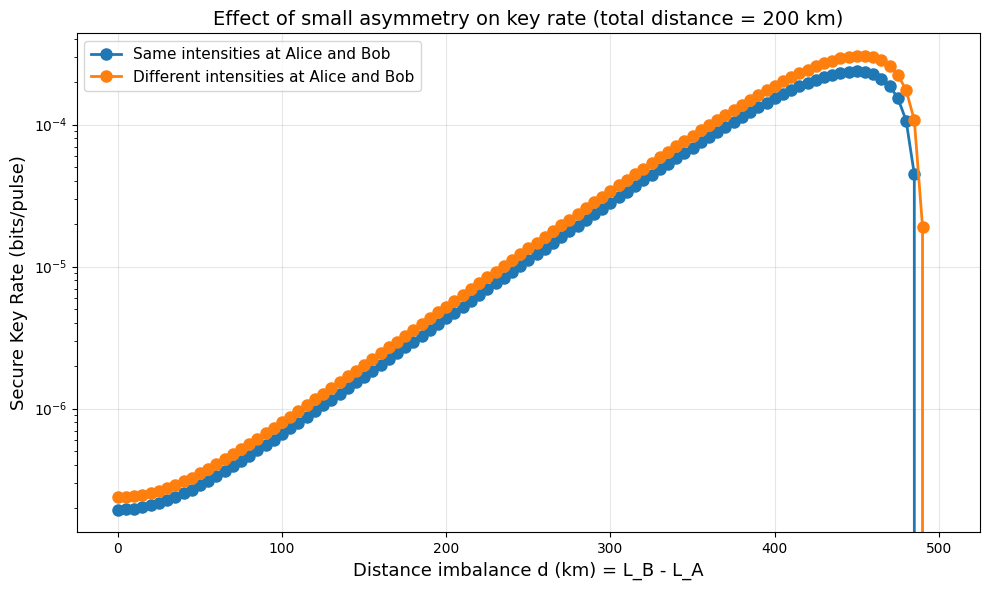

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd


# 2. Fixed parameters (system-wide)
# ------------------------------------------------------------

p_v_A = None
p_v_B = None

# System-wide fixed parameters (copied from cell 0O_FAdfbT5Of example)
N = 1e13
alpha = 0.165
Y0 = 1e-8
ed = 0.03
f = 1.16
epsilon = 1e-10
E_Z_before = 0.25
E_Z_after = 0.003
# p_x = 0.05 # Weak decoy probability

# ------------------------------------------------------------
# 3. Define the two configurations
# ------------------------------------------------------------
# ---- Symmetric configuration (from Config 6) ----
sym_config = {
    'label': 'Same intensities at Alice and Bob',
    'mu_x': 0.100, 'p_x': 0.133,
    'mu_y_A': 0.387, 'mu_y_B': 0.387,
    'p_y_A': 0.044, 'p_y_B': 0.044,
    'mu_z_A': 0.470, 'mu_z_B': 0.470,
    'p_z_A': 0.20, 'p_z_B': 0.20
}

# ---- Asymmetric configuration (from Config 1) ----
asym_config = {
    'label': 'Different intensities at Alice and Bob',
    'mu_x': 0.100, 'p_x': 0.05,
    'mu_y_A': 0.342, 'mu_y_B': 0.345,
    'p_y_A': 0.05, 'p_y_B': 0.05,
    'mu_z_A': 0.463, 'mu_z_B': 0.459,
    'p_z_A': 0.2, 'p_z_B': 0.2
}

# ------------------------------------------------------------
# 4. Sweep asymmetry levels
# ------------------------------------------------------------
total = 500.0
# percentages from 0% to 10% in steps of 5% (small asymmetry)
percentages = np.arange(0, 101, 1)   # 0,1,2,...,10
diffs_km = total * (percentages / 100.0)

results = []

for cfg in [sym_config, asym_config]:
    label = cfg['label']
    mu_x = cfg['mu_x']; p_x = cfg['p_x']
    mu_y_A = cfg['mu_y_A']; mu_y_B = cfg['mu_y_B']
    p_y_A = cfg['p_y_A']; p_y_B = cfg['p_y_B']
    mu_z_A = cfg['mu_z_A']; mu_z_B = cfg['mu_z_B']
    p_z_A = cfg['p_z_A']; p_z_B = cfg['p_z_B']

    rates = []
    for pct, diff in zip(percentages, diffs_km):
        L_A = (total - diff) / 2.0
        L_B = total - L_A
        R_value, _ = key_rate_asymmetric(
            L_A=L_A, L_B=L_B,
            mu_y_A=mu_y_A, mu_y_B=mu_y_B,
            p_y_A=p_y_A, p_y_B=p_y_B,
            mu_z_A=mu_z_A, mu_z_B=mu_z_B,
            p_z_A=p_z_A, p_z_B=p_z_B,
            mu_x=mu_x,
            p_x=p_x,
            p_v_A=p_v_A, p_v_B=p_v_B,
            N=N, alpha=alpha, Y0=Y0, ed=ed,
            f=f, epsilon=epsilon,
            E_Z_before=E_Z_before, E_Z_after=E_Z_after
        )
        rates.append(R_value)

    results.append({
        'label': label,
        'percentages': percentages,
        'diffs_km': diffs_km,
        'rates': rates,
        'params': cfg
    })

# ------------------------------------------------------------
# 5. Print tables
# ------------------------------------------------------------
for res in results:
    cfg = res['params']
    print("="*80)
    print(f"Configuration: {res['label']}")
    print("="*80)
    print(f"mu_y_A = {cfg['mu_y_A']:.3f}, mu_y_B = {cfg['mu_y_B']:.3f}, "
          f"mu_z_A = {cfg['mu_z_A']:.3f}, mu_z_B = {cfg['mu_z_B']:.3f}, mu_x = {cfg['mu_x']:.3f}")
    print(f"p_y_A = {cfg['p_y_A']:.3f}, p_y_B = {cfg['p_y_B']:.3f}, "
          f"p_z_A = {cfg['p_z_A']:.3f}, p_z_B = {cfg['p_z_B']:.3f}, p_x = {p_x:.3f}")
    print("\nDiff (%) | L_A (km) | L_B (km) | Key rate (bits/pulse)")
    print("-------------------------------------------------------------")
    for pct, L_A, L_B, R_value in zip(res['percentages'], # Changed R to R_value
                                 [(total - d)/2.0 for d in res['diffs_km']],
                                 [(total + d)/2.0 for d in res['diffs_km']],
                                 res['rates']):
        print(f"{pct:8.0f}% | {L_A:8.2f} | {L_B:8.2f} | {R_value:.6e}") # Changed R to R_value
    print("\n")

# ------------------------------------------------------------
# 6. Plot both curves on one graph
# ------------------------------------------------------------
plt.figure(figsize=(10,6))
for res in results:
    plt.plot(res['diffs_km'], res['rates'], 'o-', label=res['label'], linewidth=2, markersize=8)

plt.xlabel('Distance imbalance d (km) = L_B - L_A', fontsize=13)
plt.ylabel('Secure Key Rate (bits/pulse)', fontsize=13)
plt.title('Effect of small asymmetry on key rate (total distance = 200 km)', fontsize=14)
plt.grid(True, alpha=0.3)
plt.yscale('log')
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()

# Time-complex calculations: Intensity optimization and final results

1. The below cell optimizes the channel parameters: $μ_x^A$, $μ_x^B$,$μ_y^A$, $μ_y^B$, $p_y^A$, $p_y^B$, $μ_z^A$, $μ_z^B$, $p_z^A$, $p_z^B$,$p_x$, $p_v^A$, $p_v^B$ across distance asymmetries (200 km) form 0% to 100% asymmetry.

  Generally, $μ_x$ and $p_x$ (decoy intensity and probability) are taken common for Alice and Bob.

Optimising with multi-start SLSQP ...

Asymmetry: 0%  (L_A=100.0, L_B=100.0)
------------------------------------------------------------
  Sym: R=6.45e-04, mu_x=0.019, mu_y=0.400, mu_z=0.400, p_x=0.010, p_y=0.200, p_z=0.010
  Asym: R=7.03e-04, mu_xA=0.072, mu_yA=0.400, mu_zA=0.485, p_yA=0.200, p_zA=0.010, mu_xB=0.075, mu_yB=0.400, mu_zB=0.402, p_yB=0.250, p_zB=0.010, p_x=0.010

Asymmetry: 1%  (L_A=99.0, L_B=101.0)
------------------------------------------------------------
  Sym: R=6.46e-04, mu_x=0.030, mu_y=0.400, mu_z=0.400, p_x=0.010, p_y=0.200, p_z=0.010
  Asym: R=6.99e-04, mu_xA=0.074, mu_yA=0.400, mu_zA=0.400, p_yA=0.200, p_zA=0.010, mu_xB=0.086, mu_yB=0.400, mu_zB=0.433, p_yB=0.250, p_zB=0.010, p_x=0.010

Asymmetry: 2%  (L_A=98.0, L_B=102.0)
------------------------------------------------------------
  Sym: R=6.47e-04, mu_x=0.019, mu_y=0.400, mu_z=0.402, p_x=0.010, p_y=0.200, p_z=0.010
  Asym: R=6.96e-04, mu_xA=0.048, mu_yA=0.400, mu_zA=0.479, p_yA=0.200, p_zA=0.010, mu_xB=0.

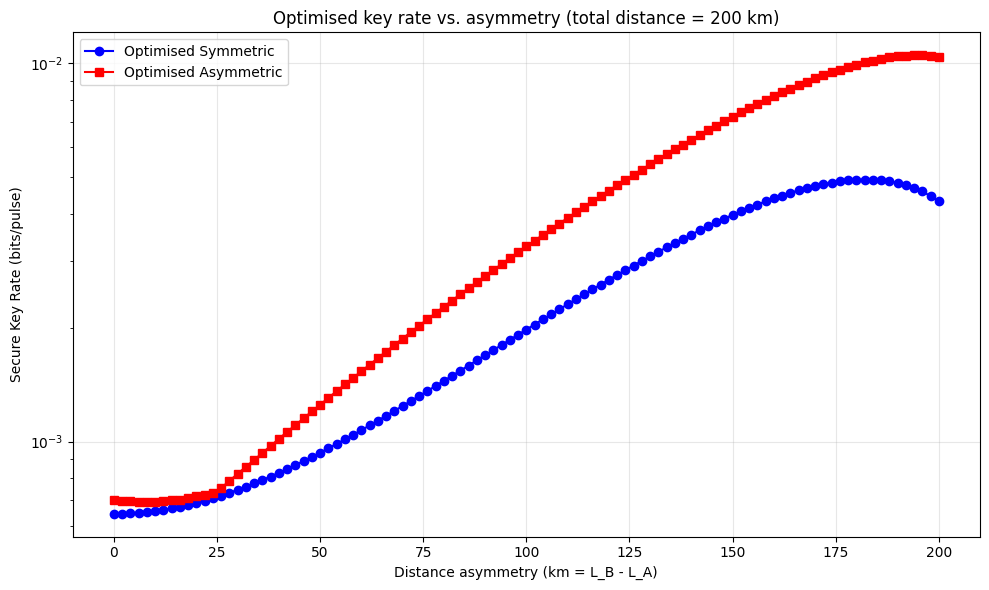

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

# ------------------------------------------------------------
# 1. Helper functions (same as before – with separate mu_x)
# ------------------------------------------------------------
def H2(x):
    if x <= 0 or x >= 1:
        return 0.0
    return -x * np.log2(x) - (1 - x) * np.log2(1 - x)

def gain(mu_a, mu_b, eta_A, eta_B, Y0):
    return 1.0 - (1.0 - Y0) * np.exp(-eta_A * mu_a - eta_B * mu_b)

def key_rate_asymmetric(
    L_A, L_B,
    mu_x_A, mu_x_B,
    mu_y_A, mu_y_B,
    p_y_A, p_y_B,
    mu_z_A, mu_z_B,
    p_z_A, p_z_B,
    p_x=0.05,
    p_v_A=None, p_v_B=None,
    N=1e13, alpha=0.165, Y0=1e-8, ed=0.03,
    f=1.16, epsilon=1e-10,
    E_Z_before=0.25, E_Z_after=0.003
):
    # ... (same as before, unchanged)
    if p_v_A is None:
        p_v_A = 1.0 - p_x - p_y_A - p_z_A
    if p_v_B is None:
        p_v_B = 1.0 - p_x - p_y_B - p_z_B

    eta_A = 10 ** (-alpha * L_A / 10.0)
    eta_B = 10 ** (-alpha * L_B / 10.0)

    Q_vv = gain(0, 0, eta_A, eta_B, Y0)
    Q_vx = gain(0, mu_x_B, eta_A, eta_B, Y0)
    Q_xv = gain(mu_x_A, 0, eta_A, eta_B, Y0)
    Q_vy = gain(0, mu_y_B, eta_A, eta_B, Y0)
    Q_yv = gain(mu_y_A, 0, eta_A, eta_B, Y0)
    Q_vz = gain(0, mu_z_B, eta_A, eta_B, Y0)
    Q_zv = gain(mu_z_A, 0, eta_A, eta_B, Y0)
    Q_xx = gain(mu_x_A, mu_x_B, eta_A, eta_B, Y0)
    Q_yy = gain(mu_y_A, mu_y_B, eta_A, eta_B, Y0)
    Q_zz = gain(mu_z_A, mu_z_B, eta_A, eta_B, Y0)
    Q_yz = gain(mu_y_A, mu_z_B, eta_A, eta_B, Y0)
    Q_zy = gain(mu_z_A, mu_y_B, eta_A, eta_B, Y0)

    num_A = mu_x_A * Q_yv * np.exp(mu_y_A) - mu_y_A * Q_xv * np.exp(mu_x_A)
    den_A = mu_x_A * mu_y_A * (mu_y_A - mu_x_A)
    Y1_A = max(0.0, num_A / den_A) if den_A > 0 else 0.0

    num_B = mu_x_B * Q_vy * np.exp(mu_y_B) - mu_y_B * Q_vx * np.exp(mu_x_B)
    den_B = mu_x_B * mu_y_B * (mu_y_B - mu_x_B)
    Y1_B = max(0.0, num_B / den_B) if den_B > 0 else 0.0

    E_X = ed
    T_xx = Q_xx * E_X

    w_A = p_v_B * p_y_A
    w_B = p_v_A * p_y_B
    Y1_avg = (w_A * Y1_A + w_B * Y1_B) / (w_A + w_B) if (w_A + w_B) > 0 else 0.0
    mu_x_eff = np.sqrt(mu_x_A * mu_x_B)
    e1_ph = (T_xx * np.exp(2*mu_x_eff) - 0.5 * Y0) / (mu_x_eff * Y1_avg) if Y1_avg > 0 else 0.5

    mu_y_A_exp = mu_y_A * np.exp(-mu_y_A)
    mu_y_B_exp = mu_y_B * np.exp(-mu_y_B)
    n1 = N * (p_v_A * p_y_B * mu_y_B_exp * Y1_B + p_y_A * p_v_B * mu_y_A_exp * Y1_A)

    H2_before = H2(E_Z_before)
    g = (1.0 - H2_before) / (1.0 - H2_before + E_Z_before)

    n1_after = n1 * g

    P_Z = (p_v_A * p_v_B * Q_vv +
           p_v_A * p_y_B * Q_vy + p_y_A * p_v_B * Q_yv +
           p_v_A * p_z_B * Q_vz + p_z_A * p_v_B * Q_zv +
           p_y_A * p_z_B * Q_yz + p_z_A * p_y_B * Q_zy +
           p_y_A * p_y_B * Q_yy + p_z_A * p_z_B * Q_zz)

    n_Z = N * P_Z
    N_survived = n_Z * g
    leak_EC = f * N_survived * H2(E_Z_after)

    signal = n1_after * (1.0 - H2(e1_ph))

    penalty = np.log2(2.0 / epsilon) + 2.0 * np.log2(1.0 / epsilon)
    if n1_after > 0:
        penalty += np.log2(1.0 / epsilon) * np.sqrt(2.0 / n1_after)

    R = (signal - leak_EC - penalty) / N
    R = max(0.0, R)
    return R

# ------------------------------------------------------------
# 2. Fixed system parameters
# ------------------------------------------------------------
N = 1e13
alpha = 0.165
Y0 = 1e-8
ed = 0.03
f = 1.16
epsilon = 1e-10
E_Z_before = 0.25
E_Z_after = 0.003
total = 200.0

# ------------------------------------------------------------
# 3. Objective functions for SLSQP with constraints
# ------------------------------------------------------------
def objective_sym(x, L_A, L_B):
    # x = [mu_x, mu_y, mu_z, p_x, p_y, p_z]
    mu_x, mu_y, mu_z, p_x, p_y, p_z = x
    R = key_rate_asymmetric(
        L_A, L_B,
        mu_x_A=mu_x, mu_x_B=mu_x,
        mu_y_A=mu_y, mu_y_B=mu_y,
        p_y_A=p_y, p_y_B=p_y,
        mu_z_A=mu_z, mu_z_B=mu_z,
        p_z_A=p_z, p_z_B=p_z,
        p_x=p_x,
        p_v_A=None, p_v_B=None,
        N=N, alpha=alpha, Y0=Y0, ed=ed,
        f=f, epsilon=epsilon,
        E_Z_before=E_Z_before, E_Z_after=E_Z_after
    )
    return -R

def objective_asym(x, L_A, L_B):
    # x = [mu_xA, mu_yA, mu_zA, p_yA, p_zA,
    #      mu_xB, mu_yB, mu_zB, p_yB, p_zB,
    #      p_x]
    (mu_xA, mu_yA, mu_zA, p_yA, p_zA,
     mu_xB, mu_yB, mu_zB, p_yB, p_zB,
     p_x) = x
    R = key_rate_asymmetric(
        L_A, L_B,
        mu_x_A=mu_xA, mu_x_B=mu_xB,
        mu_y_A=mu_yA, mu_y_B=mu_yB,
        p_y_A=p_yA, p_y_B=p_yB,
        mu_z_A=mu_zA, mu_z_B=mu_zB,
        p_z_A=p_zA, p_z_B=p_zB,
        p_x=p_x,
        p_v_A=None, p_v_B=None,
        N=N, alpha=alpha, Y0=Y0, ed=ed,
        f=f, epsilon=epsilon,
        E_Z_before=E_Z_before, E_Z_after=E_Z_after
    )
    return -R

# ------------------------------------------------------------
# 4. Constraint definitions for SLSQP
# ------------------------------------------------------------
# Symmetric: mu_x < mu_y < mu_z, p_x+p_y+p_z < 1, all >= 0
def sym_constraint(x):
    mu_x, mu_y, mu_z, p_x, p_y, p_z = x
    # enforce ordering: mu_y - mu_x > 0, mu_z - mu_y > 0
    return [mu_y - mu_x, mu_z - mu_y, 1 - p_x - p_y - p_z, p_x, p_y, p_z]
# Actually SLSQP uses equality/inequality constraints; we'll define them as >= 0
def sym_constraint_fun(x):
    mu_x, mu_y, mu_z, p_x, p_y, p_z = x
    return np.array([mu_y - mu_x, mu_z - mu_y, 1 - p_x - p_y - p_z, p_x, p_y, p_z])

# Asymmetric: similar per side, plus p_x common
def asym_constraint_fun(x):
    (mu_xA, mu_yA, mu_zA, p_yA, p_zA,
     mu_xB, mu_yB, mu_zB, p_yB, p_zB,
     p_x) = x
    return np.array([
        mu_yA - mu_xA, mu_zA - mu_yA,  # Alice ordering
        1 - p_x - p_yA - p_zA, p_yA, p_zA,  # Alice probabilities
        mu_yB - mu_xB, mu_zB - mu_yB,  # Bob ordering
        1 - p_x - p_yB - p_zB, p_yB, p_zB,  # Bob probabilities
    ])


# Bounds (same as before)
# Symmetric: [mu_x, mu_y, mu_z,
#             p_x, p_y, p_z]
bounds_sym = [(0.01, 0.15), (0.20, 0.40), (0.25, 0.50),
              (0.01, 0.20), (0.01, 0.20), (0.01, 0.25)]

# Asymmetric: [mu_xA, mu_yA, mu_zA,
#              p_yA, p_zA,
#              mu_xB, mu_yB, mu_zB,
#              p_yB, p_zB,
#              p_x]
bounds_asym = [(0.01, 0.15), (0.20, 0.40), (0.25, 0.50),
               (0.01, 0.20), (0.01, 0.25),
               (0.01, 0.15), (0.20, 0.40), (0.30, 0.50),
               (0.01, 0.25), (0.01, 0.25),
               (0.01, 0.20)]

# ------------------------------------------------------------
# 5. Optimisation loop with multi-start
# ------------------------------------------------------------
def run_optimization(objective, bounds, constr, n_start=20, L_A=100, L_B=100):
    best_x = None
    best_R = -np.inf
    for i in range(n_start):
        # random initial guess within bounds
        x0 = np.array([np.random.uniform(low, high) for low, high in bounds])
        # try to satisfy constraints by adjusting
        # SLSQP will handle them, but a good initial guess helps
        res = minimize(objective, x0, args=(L_A, L_B),
                       method='SLSQP',
                       bounds=bounds,
                       constraints={'type': 'ineq', 'fun': constr},
                       options={'maxiter': 500, 'ftol': 1e-8})
        if res.success and -res.fun > best_R:
            best_R = -res.fun
            best_x = res.x
    return best_x, best_R

# ------------------------------------------------------------
# 6. Main loop over asymmetry levels
# ------------------------------------------------------------
asymmetry_levels = np.arange(0, 101, 1)  # 0 to 100 in steps of 1
results_sym = []
results_asym = []

print("Optimising with multi-start SLSQP ...")
print("="*80)

for pct in asymmetry_levels:
    diff = total * (pct / 100.0)
    L_A = (total - diff) / 2.0
    L_B = total - L_A

    print(f"\nAsymmetry: {pct:.0f}%  (L_A={L_A:.1f}, L_B={L_B:.1f})")
    print("-"*60)

    # Symmetric
    best_x_sym, best_R_sym = run_optimization(objective_sym, bounds_sym, sym_constraint_fun, n_start=10, L_A=L_A, L_B=L_B)
    if best_x_sym is not None:
        mu_x, mu_y, mu_z, p_x, p_y, p_z = best_x_sym
        print(f"  Sym: R={best_R_sym:.2e}, mu_x={mu_x:.3f}, mu_y={mu_y:.3f}, mu_z={mu_z:.3f}, p_x={p_x:.3f}, p_y={p_y:.3f}, p_z={p_z:.3f}")
    else:
        print("  Sym: no feasible solution found")
    results_sym.append((pct, L_A, L_B, best_R_sym, best_x_sym))

    # Asymmetric
    best_x_asym, best_R_asym = run_optimization(objective_asym, bounds_asym, asym_constraint_fun, n_start=10, L_A=L_A, L_B=L_B)
    if best_x_asym is not None:
        (mu_xA, mu_yA, mu_zA, p_yA, p_zA,
         mu_xB, mu_yB, mu_zB, p_yB, p_zB,
         p_x) = best_x_asym
        print(f"  Asym: R={best_R_asym:.2e}, mu_xA={mu_xA:.3f}, mu_yA={mu_yA:.3f}, mu_zA={mu_zA:.3f}, p_yA={p_yA:.3f}, p_zA={p_zA:.3f}, mu_xB={mu_xB:.3f}, mu_yB={mu_yB:.3f}, mu_zB={mu_zB:.3f}, p_yB={p_yB:.3f}, p_zB={p_zB:.3f}, p_x={p_x:.3f}")
    else:
        print("  Asym: no feasible solution found")
    results_asym.append((pct, L_A, L_B, best_R_asym, best_x_asym))

# ------------------------------------------------------------
# 7. Print summary and plot
# ------------------------------------------------------------
print("\n" + "="*80)
print("SUMMARY: Optimised parameters for each asymmetry level")
print("="*80)

print("\n--- Symmetric case ---")
print("Asym% | R_opt | mu_x | mu_y | mu_z | p_x | p_y | p_z")
for r in results_sym:
    pct, L_A, L_B, R, x = r
    if x is not None and R > 0:
        mu_x, mu_y, mu_z, p_x, p_y, p_z = x
        print(f"{pct:5.0f} | {R:.2e} | {mu_x:.3f} | {mu_y:.3f} | {mu_z:.3f} | {p_x:.3f} | {p_y:.3f} | {p_z:.3f}")
    else:
        print(f"{pct:5.0f} | {R:.2e} |     - |     - |     - |     - |     - |     -")

print("\n--- Asymmetric case ---")
print("Asym% | R_opt | mu_xA | mu_yA | mu_zA | p_yA | p_zA | mu_xB | mu_yB | mu_zB | p_yB | p_zB | p_x")
for r in results_asym:
    pct, L_A, L_B, R, x = r
    if x is not None and R > 0:
        (mu_xA, mu_yA, mu_zA, p_yA, p_zA,
         mu_xB, mu_yB, mu_zB, p_yB, p_zB,
         p_x) = x
        print(f"{pct:5.0f} | {R:.2e} | {mu_xA:.3f} | {mu_yA:.3f} | {mu_zA:.3f} | {p_yA:.3f} | {p_zA:.3f} | {mu_xB:.3f} | {mu_yB:.3f} | {mu_zB:.3f} | {p_yB:.3f} | {p_zB:.3f} | {p_x:.3f}")
    else:
        print(f"{pct:5.0f} | {R:.2e} |     - |     - |     - |     - |     - |     - |     - |     - |     - |     - |     -")

# Plot comparison
diffs = [total * (pct/100.0) for pct in asymmetry_levels]
R_sym_vals = [r[3] for r in results_sym]
R_asym_vals = [r[3] for r in results_asym]

plt.figure(figsize=(10,6))
plt.plot(diffs, R_sym_vals, 'o-', label='Optimised Symmetric', color='blue')
plt.plot(diffs, R_asym_vals, 's-', label='Optimised Asymmetric', color='red')
plt.xlabel('Distance asymmetry (km = L_B - L_A)')
plt.ylabel('Secure Key Rate (bits/pulse)')
plt.title('Optimised key rate vs. asymmetry (total distance = 200 km)')
plt.grid(True, alpha=0.3)
plt.yscale('log')
plt.legend()
plt.tight_layout()
plt.show()

2. (a) The below cell plots the channel optimization, given a fixed distance asymmetry (80-120 km in this case) (40% distance asymmetry).

Fixed distances: L_A = 120.0 km, L_B = 80.0 km (diff = -40.0 km)

=== Best solution found ===
Key rate = 1.269790e-03
Alice: mu_xA=0.0786, mu_yA=0.4000, mu_zA=0.4407, p_yA=0.0100, p_zA=0.0100
Bob:   mu_xB=0.0200, mu_yB=0.4000, mu_zB=0.4578, p_yB=0.2500, p_zB=0.0100
Common p_x = 0.0100
p_vA = 0.9700, p_vB = 0.7300


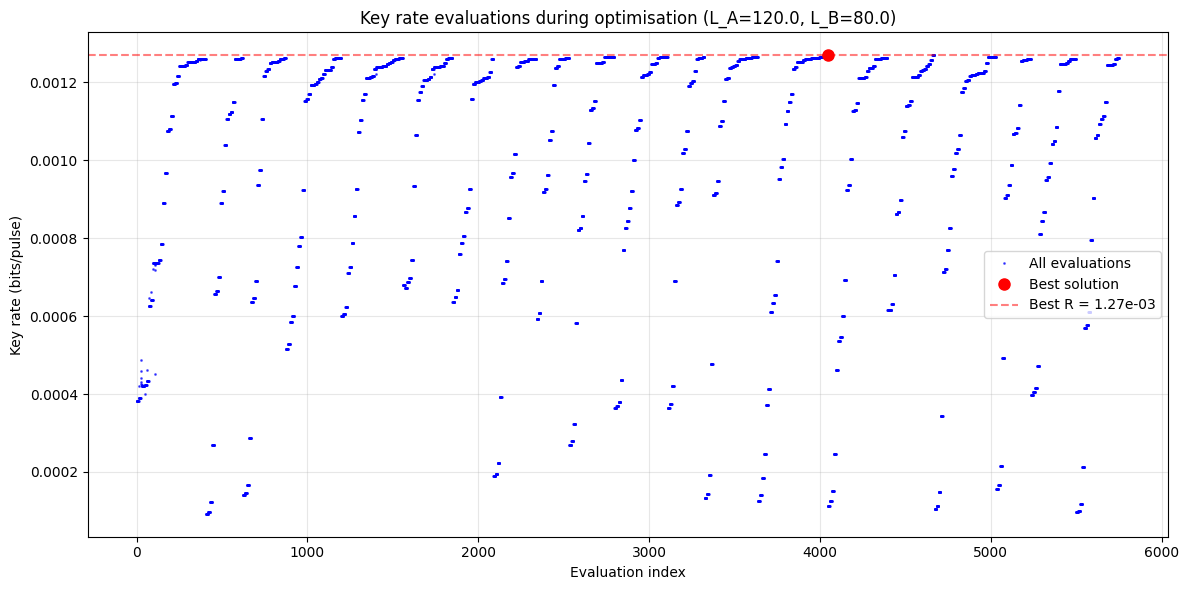


Total evaluations: 5752
Mean key rate: 9.86e-04
Std deviation: 3.38e-04


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

# ------------------------------------------------------------
# 1. Assume key_rate_asymmetric and helpers are already defined.
#    If not, copy them from your previous code.
# ------------------------------------------------------------

# ------------------------------------------------------------
# 2. Fixed system parameters
# ------------------------------------------------------------
N = 1e13
alpha = 0.165
Y0 = 1e-8
ed = 0.03
f = 1.16
epsilon = 1e-10
E_Z_before = 0.25
E_Z_after = 0.003

# Fixed distances: L_A = 120 km, L_B = 80 km
L_A = 120.0
L_B = 80.0
print(f"Fixed distances: L_A = {L_A} km, L_B = {L_B} km (diff = {L_B-L_A} km)")

# ------------------------------------------------------------
# 3. Objective function for asymmetric case (same as before)
# ------------------------------------------------------------
def objective_asym(x):
    # x = [mu_xA, mu_yA, mu_zA, p_yA, p_zA,
    #      mu_xB, mu_yB, mu_zB, p_yB, p_zB,
    #      p_x]
    (mu_xA, mu_yA, mu_zA, p_yA, p_zA,
     mu_xB, mu_yB, mu_zB, p_yB, p_zB,
     p_x) = x
    R = key_rate_asymmetric(
        L_A, L_B,
        mu_x_A=mu_xA, mu_x_B=mu_xB,
        mu_y_A=mu_yA, mu_y_B=mu_yB,
        p_y_A=p_yA, p_y_B=p_yB,
        mu_z_A=mu_zA, mu_z_B=mu_zB,
        p_z_A=p_zA, p_z_B=p_zB,
        p_x=p_x,
        p_v_A=None, p_v_B=None,
        N=N, alpha=alpha, Y0=Y0, ed=ed,
        f=f, epsilon=epsilon,
        E_Z_before=E_Z_before, E_Z_after=E_Z_after
    )
    return -R

# ------------------------------------------------------------
# 4. Constraints (as before)
# ------------------------------------------------------------
def asym_constraint_fun(x):
    (mu_xA, mu_yA, mu_zA, p_yA, p_zA,
     mu_xB, mu_yB, mu_zB, p_yB, p_zB,
     p_x) = x
    return np.array([
        mu_yA - mu_xA, mu_zA - mu_yA,
        1 - p_x - p_yA - p_zA, p_yA, p_zA,
        mu_yB - mu_xB, mu_zB - mu_yB,
        1 - p_x - p_yB - p_zB, p_yB, p_zB,
    ])

# Bounds (slightly widened)
bounds_asym = [(0.01, 0.25), (0.20, 0.40), (0.25, 0.50),
               (0.01, 0.20), (0.01, 0.25),
               (0.02, 0.20), (0.20, 0.40), (0.30, 0.50),
               (0.01, 0.25), (0.01, 0.25),
               (0.01, 0.20)]

# ------------------------------------------------------------
# 5. Multi-start optimisation with history recording
# ------------------------------------------------------------
eval_history = []   # global list to store (x, R) for each evaluation

def objective_asym_with_history(x):
    R = -objective_asym(x)   # objective returns negative R, so we get R
    eval_history.append((x.copy(), R))
    return -R   # return negative R for minimizer

def run_optimization_with_history(n_start=20):
    best_x = None
    best_R = -np.inf
    for i in range(n_start):
        x0 = np.array([np.random.uniform(low, high) for low, high in bounds_asym])
        res = minimize(objective_asym_with_history, x0,
                       method='SLSQP',
                       bounds=bounds_asym,
                       constraints={'type': 'ineq', 'fun': asym_constraint_fun},
                       options={'maxiter': 500, 'ftol': 1e-8})
        if res.success and -res.fun > best_R:
            best_R = -res.fun
            best_x = res.x
    return best_x, best_R

# Clear history before optimisation
eval_history.clear()
best_x, best_R = run_optimization_with_history(n_start=20)

print("\n=== Best solution found ===")
if best_x is not None:
    (mu_xA, mu_yA, mu_zA, p_yA, p_zA,
     mu_xB, mu_yB, mu_zB, p_yB, p_zB,
     p_x) = best_x
    print(f"Key rate = {best_R:.6e}")
    print(f"Alice: mu_xA={mu_xA:.4f}, mu_yA={mu_yA:.4f}, mu_zA={mu_zA:.4f}, p_yA={p_yA:.4f}, p_zA={p_zA:.4f}")
    print(f"Bob:   mu_xB={mu_xB:.4f}, mu_yB={mu_yB:.4f}, mu_zB={mu_zB:.4f}, p_yB={p_yB:.4f}, p_zB={p_zB:.4f}")
    print(f"Common p_x = {p_x:.4f}")
    # Also compute vacuum probabilities for completeness
    p_vA = 1.0 - p_x - p_yA - p_zA
    p_vB = 1.0 - p_x - p_yB - p_zB
    print(f"p_vA = {p_vA:.4f}, p_vB = {p_vB:.4f}")
else:
    print("No feasible solution found.")

# ------------------------------------------------------------
# 6. Plot the history
# ------------------------------------------------------------
if len(eval_history) > 0:
    # Extract rates and create an index list
    rates = [R for _, R in eval_history]
    indices = np.arange(len(rates))

    plt.figure(figsize=(12, 6))
    # Plot all evaluated points as thin lines (or markers)
    plt.plot(indices, rates, 'b.', markersize=2, alpha=0.6, label='All evaluations')
    # Highlight the best point
    best_idx = np.argmax(rates)
    plt.plot(best_idx, rates[best_idx], 'ro', markersize=8, label='Best solution')
    # Add a horizontal line for the best rate
    plt.axhline(y=best_R, color='r', linestyle='--', alpha=0.5, label=f'Best R = {best_R:.2e}')

    plt.xlabel('Evaluation index')
    plt.ylabel('Key rate (bits/pulse)')
    plt.title(f'Key rate evaluations during optimisation (L_A={L_A}, L_B={L_B})')
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()

    # Optionally, print some statistics
    print(f"\nTotal evaluations: {len(rates)}")
    print(f"Mean key rate: {np.mean(rates):.2e}")
    print(f"Std deviation: {np.std(rates):.2e}")
else:
    print("No history recorded.")

2. (b) The below cell further searches for the optimal key rate by picking 100000 random samples for each channel parameter (using Python's linear algebra libraries).
Their individual and combined effect on the key rate is shown below:

Fixed distances: L_A = 80.0 km, L_B = 120.0 km
Generating 100000 random valid parameter sets...
  Generated 500 valid samples
  Generated 1000 valid samples
  Generated 1500 valid samples
  Generated 2000 valid samples
  Generated 2500 valid samples
  Generated 3000 valid samples
  Generated 3500 valid samples
  Generated 4000 valid samples
  Generated 4500 valid samples
  Generated 5000 valid samples
  Generated 5500 valid samples
  Generated 6000 valid samples
  Generated 6500 valid samples
  Generated 7000 valid samples
  Generated 7500 valid samples
  Generated 8000 valid samples
  Generated 8500 valid samples
  Generated 9000 valid samples
  Generated 9500 valid samples
  Generated 10000 valid samples
  Generated 10500 valid samples
  Generated 11000 valid samples
  Generated 11500 valid samples
  Generated 12000 valid samples
  Generated 12500 valid samples
  Generated 13000 valid samples
  Generated 13500 valid samples
  Generated 14000 valid samples
  Generated 14500 valid samp

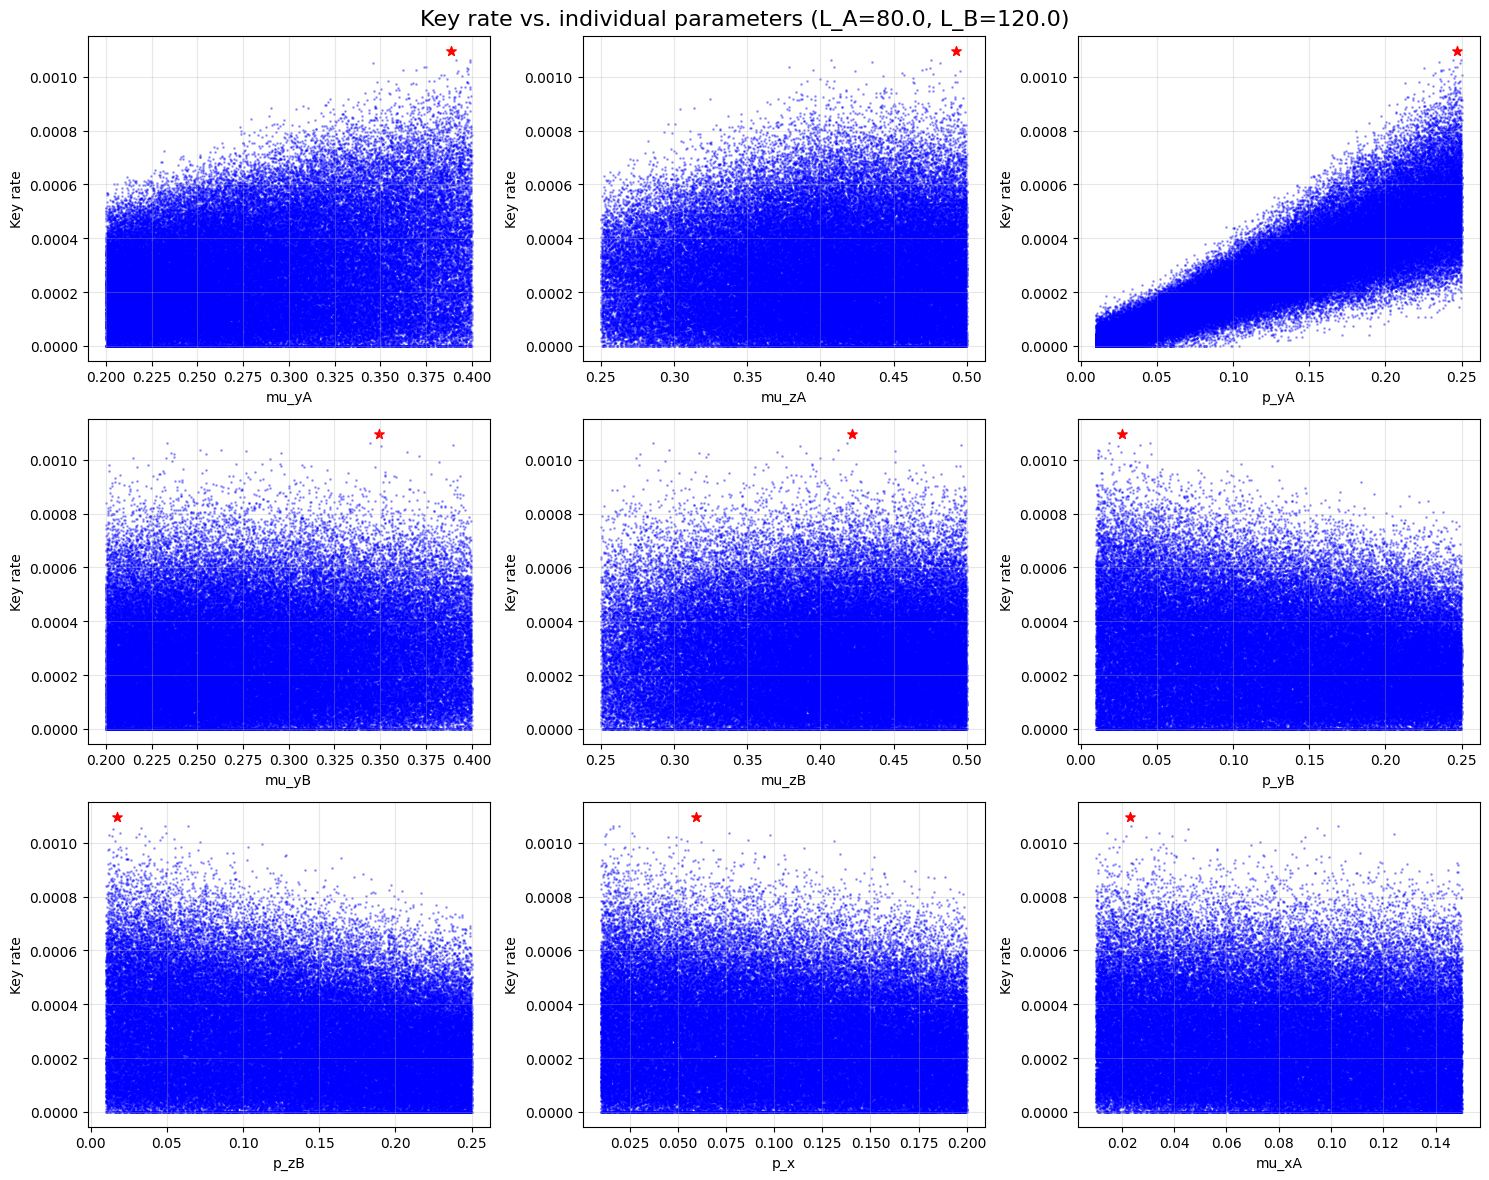

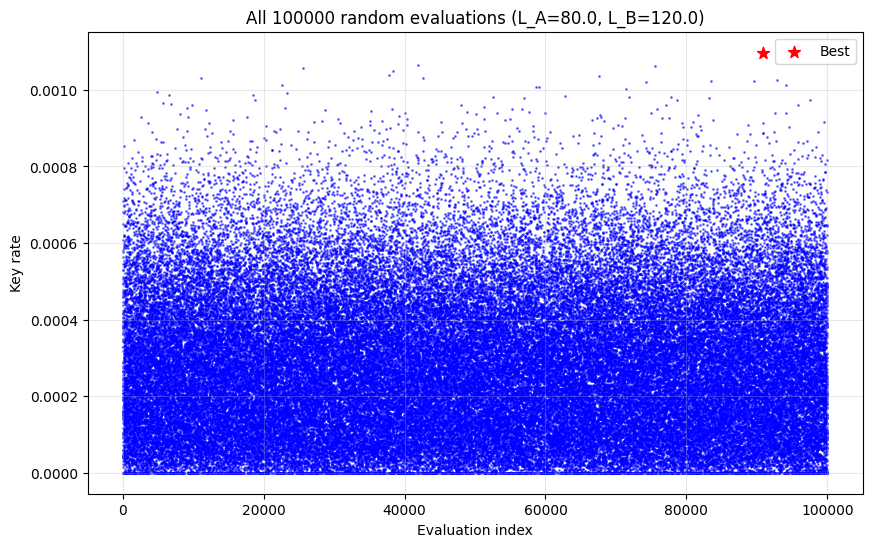

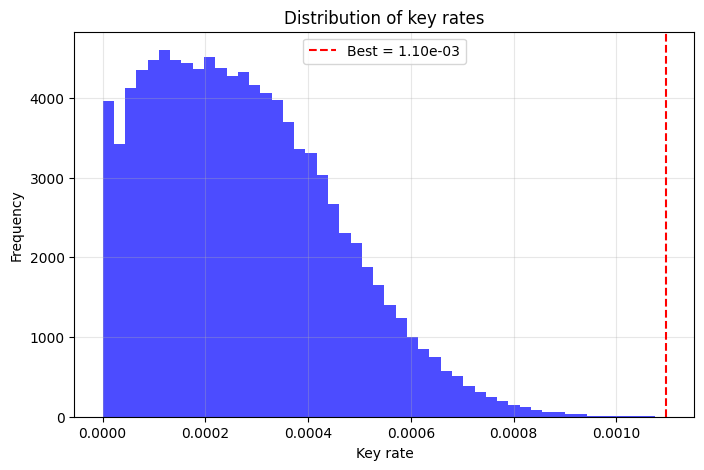


Statistics over 100000 samples:
  Mean key rate: 2.76e-04
  Std dev: 1.78e-04
  Min: 0.00e+00
  Max: 1.10e-03


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize
import time

# ------------------------------------------------------------
# 1. Helper functions (same as skeleton)
# ------------------------------------------------------------
def H2(x):
    if x <= 0 or x >= 1:
        return 0.0
    return -x * np.log2(x) - (1 - x) * np.log2(1 - x)

def gain(mu_a, mu_b, eta_A, eta_B, Y0):
    return 1.0 - (1.0 - Y0) * np.exp(-eta_A * mu_a - eta_B * mu_b)

def key_rate_asymmetric(
    L_A, L_B,
    mu_x_A, mu_x_B,
    mu_y_A, mu_y_B,
    p_y_A, p_y_B,
    mu_z_A, mu_z_B,
    p_z_A, p_z_B,
    p_x=0.05,
    p_v_A=None, p_v_B=None,
    N=1e13, alpha=0.165, Y0=1e-8, ed=0.03,
    f=1.16, epsilon=1e-10,
    E_Z_before=0.25, E_Z_after=0.003
):
    # ... (full implementation as in the skeleton; unchanged)
    if p_v_A is None:
        p_v_A = 1.0 - p_x - p_y_A - p_z_A
    if p_v_B is None:
        p_v_B = 1.0 - p_x - p_y_B - p_z_B

    eta_A = 10 ** (-alpha * L_A / 10.0)
    eta_B = 10 ** (-alpha * L_B / 10.0)

    Q_vv = gain(0, 0, eta_A, eta_B, Y0)
    Q_vx = gain(0, mu_x_B, eta_A, eta_B, Y0)
    Q_xv = gain(mu_x_A, 0, eta_A, eta_B, Y0)
    Q_vy = gain(0, mu_y_B, eta_A, eta_B, Y0)
    Q_yv = gain(mu_y_A, 0, eta_A, eta_B, Y0)
    Q_vz = gain(0, mu_z_B, eta_A, eta_B, Y0)
    Q_zv = gain(mu_z_A, 0, eta_A, eta_B, Y0)
    Q_xx = gain(mu_x_A, mu_x_B, eta_A, eta_B, Y0)
    Q_yy = gain(mu_y_A, mu_y_B, eta_A, eta_B, Y0)
    Q_zz = gain(mu_z_A, mu_z_B, eta_A, eta_B, Y0)
    Q_yz = gain(mu_y_A, mu_z_B, eta_A, eta_B, Y0)
    Q_zy = gain(mu_z_A, mu_y_B, eta_A, eta_B, Y0)

    num_A = mu_x_A * Q_yv * np.exp(mu_y_A) - mu_y_A * Q_xv * np.exp(mu_x_A)
    den_A = mu_x_A * mu_y_A * (mu_y_A - mu_x_A)
    Y1_A = max(0.0, num_A / den_A) if den_A > 0 else 0.0

    num_B = mu_x_B * Q_vy * np.exp(mu_y_B) - mu_y_B * Q_vx * np.exp(mu_x_B)
    den_B = mu_x_B * mu_y_B * (mu_y_B - mu_x_B)
    Y1_B = max(0.0, num_B / den_B) if den_B > 0 else 0.0

    E_X = ed
    T_xx = Q_xx * E_X

    w_A = p_v_B * p_y_A
    w_B = p_v_A * p_y_B
    Y1_avg = (w_A * Y1_A + w_B * Y1_B) / (w_A + w_B) if (w_A + w_B) > 0 else 0.0
    mu_x_eff = np.sqrt(mu_x_A * mu_x_B)
    e1_ph = (T_xx * np.exp(2*mu_x_eff) - 0.5 * Y0) / (mu_x_eff * Y1_avg) if Y1_avg > 0 else 0.5

    mu_y_A_exp = mu_y_A * np.exp(-mu_y_A)
    mu_y_B_exp = mu_y_B * np.exp(-mu_y_B)
    n1 = N * (p_v_A * p_y_B * mu_y_B_exp * Y1_B + p_y_A * p_v_B * mu_y_A_exp * Y1_A)

    H2_before = H2(E_Z_before)
    g = (1.0 - H2_before) / (1.0 - H2_before + E_Z_before)

    n1_after = n1 * g

    P_Z = (p_v_A * p_v_B * Q_vv +
           p_v_A * p_y_B * Q_vy + p_y_A * p_v_B * Q_yv +
           p_v_A * p_z_B * Q_vz + p_z_A * p_v_B * Q_zv +
           p_y_A * p_z_B * Q_yz + p_z_A * p_y_B * Q_zy +
           p_y_A * p_y_B * Q_yy + p_z_A * p_z_B * Q_zz)

    n_Z = N * P_Z
    N_survived = n_Z * g
    leak_EC = f * N_survived * H2(E_Z_after)

    signal = n1_after * (1.0 - H2(e1_ph))

    penalty = np.log2(2.0 / epsilon) + 2.0 * np.log2(1.0 / epsilon)
    if n1_after > 0:
        penalty += np.log2(1.0 / epsilon) * np.sqrt(2.0 / n1_after)

    R = (signal - leak_EC - penalty) / N
    R = max(0.0, R)
    return R

# ------------------------------------------------------------
# 2. Fixed system parameters
# ------------------------------------------------------------
N = 1e13
alpha = 0.165
Y0 = 1e-8
ed = 0.03
f = 1.16
epsilon = 1e-10
E_Z_before = 0.25
E_Z_after = 0.003

# Fixed distances (20% asymmetry)
L_A = 80.0
L_B = 120.0
print(f"Fixed distances: L_A = {L_A} km, L_B = {L_B} km")

# ------------------------------------------------------------
# 3. Bounds and constraints (as in skeleton)
# ------------------------------------------------------------
# Asymmetric bounds: [mu_xA, mu_yA, mu_zA, p_yA, p_zA,
#                     mu_xB, mu_yB, mu_zB, p_yB, p_zB, p_x]
bounds = [(0.01, 0.15), (0.20, 0.40), (0.25, 0.50),
          (0.01, 0.25), (0.01, 0.25),
          (0.01, 0.15), (0.20, 0.40), (0.25, 0.50),
          (0.01, 0.25), (0.01, 0.25),
          (0.01, 0.20)]

def is_valid(x):
    # Check ordering and probability sum constraints
    (mu_xA, mu_yA, mu_zA, p_yA, p_zA,
     mu_xB, mu_yB, mu_zB, p_yB, p_zB,
     p_x) = x
    # Alice
    if not (mu_xA < mu_yA < mu_zA):
        return False
    if not (p_x + p_yA + p_zA < 1.0):
        return False
    # Bob
    if not (mu_xB < mu_yB < mu_zB):
        return False
    if not (p_x + p_yB + p_zB < 1.0):
        return False
    return True

# ------------------------------------------------------------
# 4. Generate random valid parameter sets
# ------------------------------------------------------------
n_samples = 100000   # number of random valid points
np.random.seed(42)  # for reproducibility

samples = []
rates = []
print(f"Generating {n_samples} random valid parameter sets...")
start_time = time.time()

count = 0
while count < n_samples:
    # Generate random numbers within bounds
    x = np.array([np.random.uniform(low, high) for low, high in bounds])
    if is_valid(x):
        R = key_rate_asymmetric(
            L_A, L_B,
            mu_x_A=x[0], mu_x_B=x[5],
            mu_y_A=x[1], mu_y_B=x[6],
            p_y_A=x[3], p_y_B=x[8],
            mu_z_A=x[2], mu_z_B=x[7],
            p_z_A=x[4], p_z_B=x[9],
            p_x=x[10],
            p_v_A=None, p_v_B=None,
            N=N, alpha=alpha, Y0=Y0, ed=ed,
            f=f, epsilon=epsilon,
            E_Z_before=E_Z_before, E_Z_after=E_Z_after
        )
        samples.append(x)
        rates.append(R)
        count += 1
        if count % 500 == 0:
            print(f"  Generated {count} valid samples")
    # else: discard invalid

elapsed = time.time() - start_time
print(f"Done. Took {elapsed:.1f} seconds.")

samples = np.array(samples)
rates = np.array(rates)

# Best found
best_idx = np.argmax(rates)
best_R = rates[best_idx]
best_x = samples[best_idx]

print("\n=== Best found in random sampling ===")
print(f"Key rate = {best_R:.6e}")
(mu_xA, mu_yA, mu_zA, p_yA, p_zA,
 mu_xB, mu_yB, mu_zB, p_yB, p_zB,
 p_x) = best_x
print(f"Alice: mu_xA={mu_xA:.4f}, mu_yA={mu_yA:.4f}, mu_zA={mu_zA:.4f}, p_yA={p_yA:.4f}, p_zA={p_zA:.4f}")
print(f"Bob:   mu_xB={mu_xB:.4f}, mu_yB={mu_yB:.4f}, mu_zB={mu_zB:.4f}, p_yB={p_yB:.4f}, p_zB={p_zB:.4f}")
print(f"Common p_x = {p_x:.4f}")
p_vA = 1.0 - p_x - p_yA - p_zA
p_vB = 1.0 - p_x - p_yB - p_zB
print(f"p_vA = {p_vA:.4f}, p_vB = {p_vB:.4f}")

# ------------------------------------------------------------
# 5. Plotting
# ------------------------------------------------------------
fig, axes = plt.subplots(3, 3, figsize=(15, 12))
fig.suptitle(f'Key rate vs. individual parameters (L_A={L_A}, L_B={L_B})', fontsize=16)

# Flatten for easy indexing
ax = axes.flatten()

# Parameter names
param_names = ['mu_xA', 'mu_yA', 'mu_zA', 'p_yA', 'p_zA',
               'mu_xB', 'mu_yB', 'mu_zB', 'p_yB', 'p_zB', 'p_x']

# Plot for each parameter (skip the last one? we have 11 params, we have 9 subplots, so we'll choose the most relevant)
# We'll plot only 9: mu_yA, mu_zA, p_yA, mu_yB, mu_zB, p_yB, p_zB, p_x, and maybe mu_xA (or skip)
selected_indices = [1, 2, 3, 6, 7, 8, 9, 10, 0]  # mu_yA, mu_zA, p_yA, mu_yB, mu_zB, p_yB, p_zB, p_x, mu_xA
for i, idx in enumerate(selected_indices):
    ax[i].scatter(samples[:, idx], rates, s=1, alpha=0.3, color='blue')
    # Mark the best point
    ax[i].scatter(best_x[idx], best_R, color='red', s=50, marker='*', label='Best' if i==0 else "")
    ax[i].set_xlabel(param_names[idx])
    ax[i].set_ylabel('Key rate')
    ax[i].grid(True, alpha=0.3)

# Remove unused subplots
for j in range(len(selected_indices), len(ax)):
    fig.delaxes(ax[j])

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 6. Master plot: all evaluations vs index
# ------------------------------------------------------------
plt.figure(figsize=(10, 6))
plt.scatter(np.arange(len(rates)), rates, s=1, alpha=0.5, color='blue')
plt.scatter(best_idx, best_R, color='red', s=80, marker='*', label='Best')
plt.xlabel('Evaluation index')
plt.ylabel('Key rate')
plt.title(f'All {len(rates)} random evaluations (L_A={L_A}, L_B={L_B})')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# ------------------------------------------------------------
# 7. Histogram of key rates
# ------------------------------------------------------------
plt.figure(figsize=(8, 5))
plt.hist(rates, bins=50, alpha=0.7, color='blue')
plt.axvline(best_R, color='red', linestyle='--', label=f'Best = {best_R:.2e}')
plt.xlabel('Key rate')
plt.ylabel('Frequency')
plt.title('Distribution of key rates')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# ------------------------------------------------------------
# 8. Print some statistics
# ------------------------------------------------------------
print(f"\nStatistics over {len(rates)} samples:")
print(f"  Mean key rate: {np.mean(rates):.2e}")
print(f"  Std dev: {np.std(rates):.2e}")
print(f"  Min: {np.min(rates):.2e}")
print(f"  Max: {np.max(rates):.2e}")

3. The individual and combined effect of each channel parameter on the key rate is plotted below (given a fixed distance asymmetry).
Also, the variation of key rate based on selection of $L_A$, $L_B$ and $L_{diff}$ = $L_A$ - $L_B$ is plotted:

Baseline distances: L_A = 120.0 km, L_B = 80.0 km
Baseline key rate = 9.567774e-05


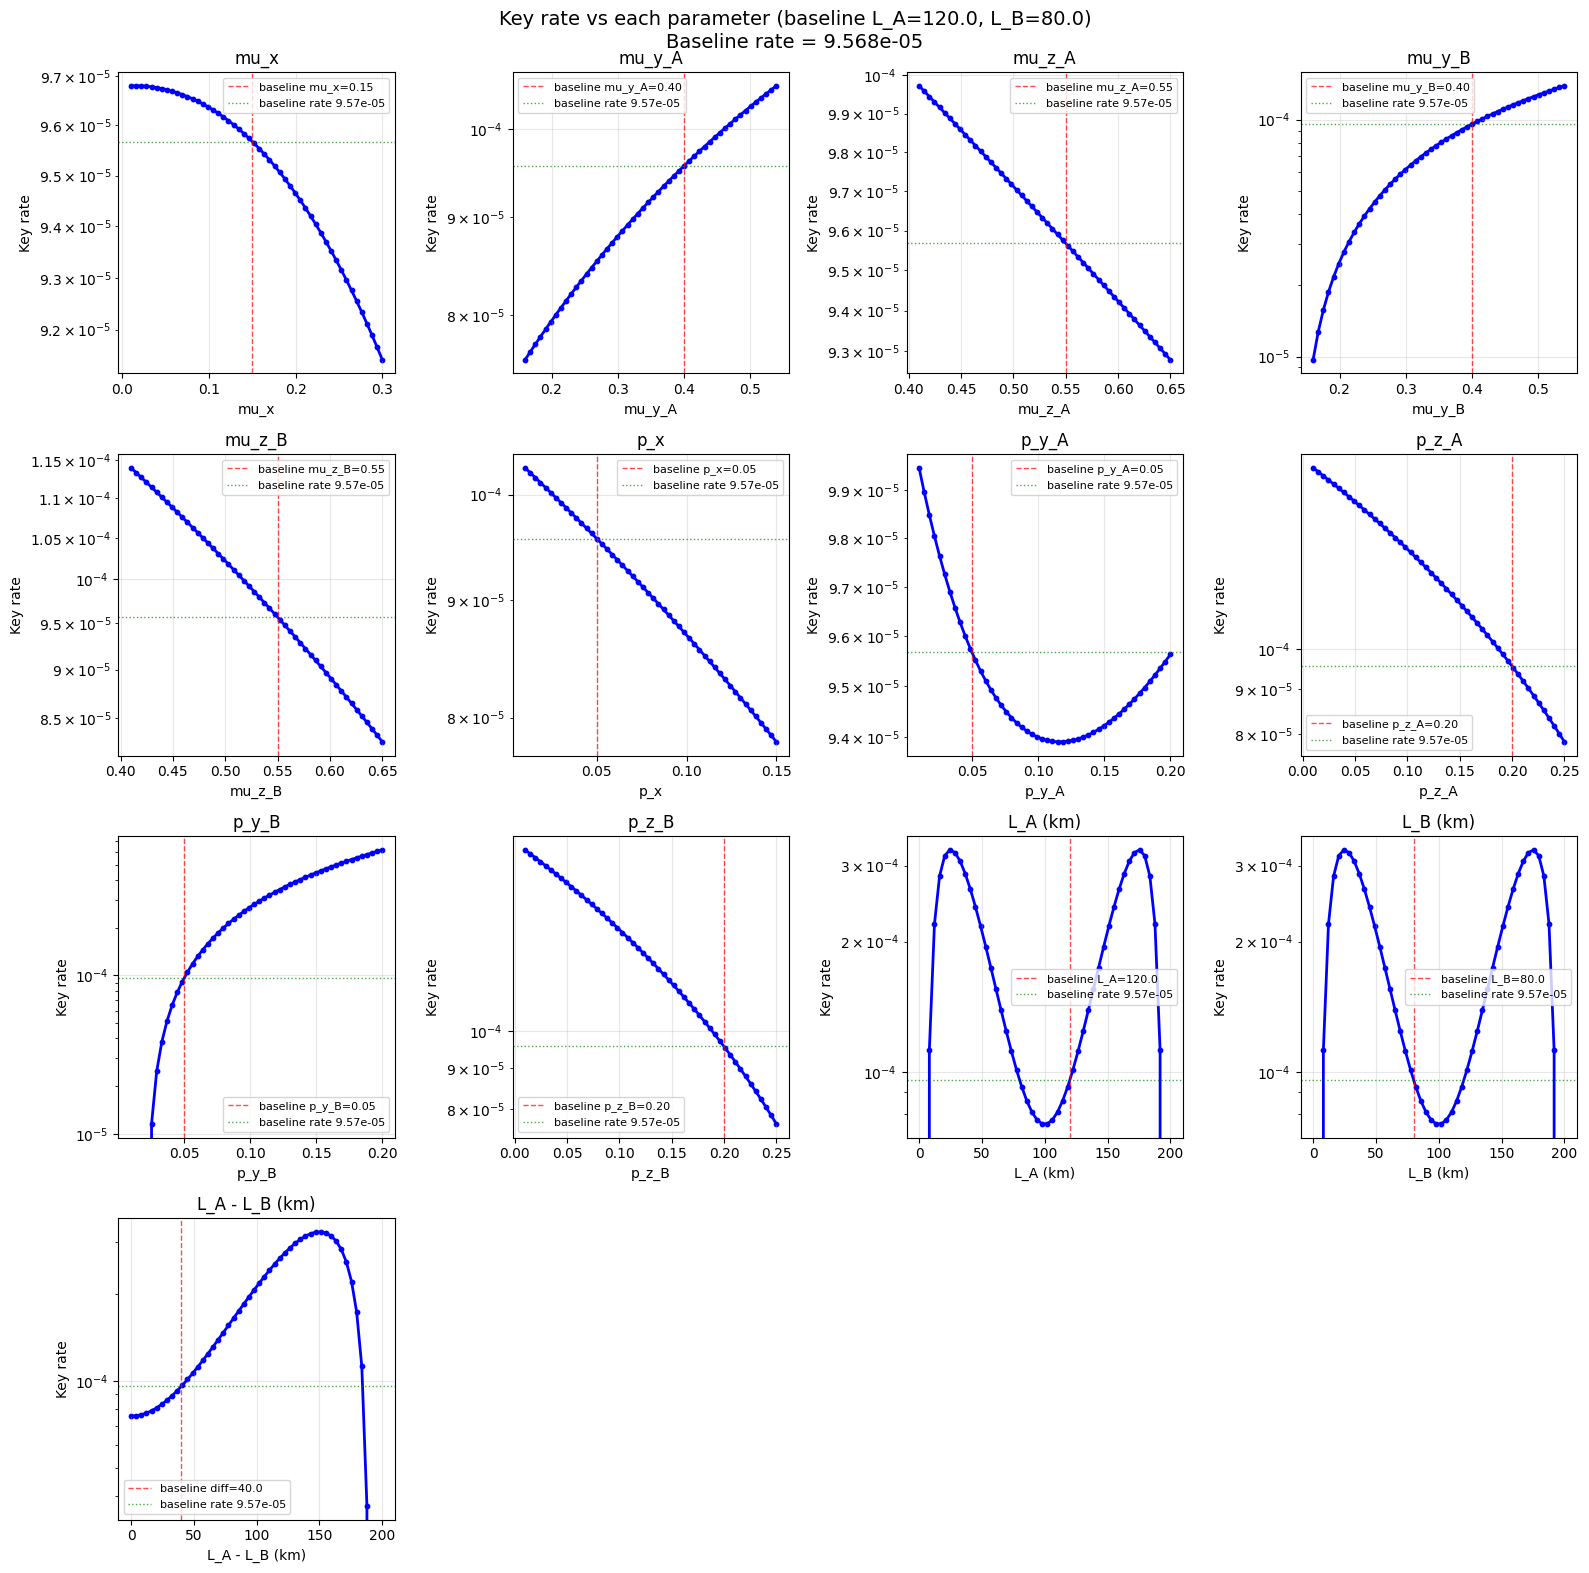

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Assume key_rate_asymmetric and helpers are defined.
# ------------------------------------------------------------

# ------------------------------------------------------------
# 2. Fixed baseline distances (20% asymmetry)
# ------------------------------------------------------------
BASE_L_A = 120.0
BASE_L_B = 80.0
TOTAL_DIST = 200.0

print(f"Baseline distances: L_A = {BASE_L_A} km, L_B = {BASE_L_B} km")

# ------------------------------------------------------------
# 3. Baseline configuration (Config 6 – symmetric mid)
# ------------------------------------------------------------
base = {
    'mu_x': 0.15,
    'mu_y_A': 0.40,
    'mu_z_A': 0.55,
    'mu_y_B': 0.40,
    'mu_z_B': 0.55,
    'p_x': 0.05,
    'p_y_A': 0.05,
    'p_z_A': 0.20,
    'p_y_B': 0.05,
    'p_z_B': 0.20,
}

# ------------------------------------------------------------
# 4. Helper to compute key rate from a parameter dictionary and distances
# ------------------------------------------------------------
def compute_rate(params, L_A, L_B):
    return key_rate_asymmetric(
        L_A, L_B,
        mu_x_A=params['mu_x'], mu_x_B=params['mu_x'],
        mu_y_A=params['mu_y_A'], mu_y_B=params['mu_y_B'],
        p_y_A=params['p_y_A'], p_y_B=params['p_y_B'],
        mu_z_A=params['mu_z_A'], mu_z_B=params['mu_z_B'],
        p_z_A=params['p_z_A'], p_z_B=params['p_z_B'],
        p_x=params['p_x'],
        p_v_A=None, p_v_B=None,
        N=1e13, alpha=0.165, Y0=1e-8, ed=0.03,
        f=1.16, epsilon=1e-10,
        E_Z_before=0.25, E_Z_after=0.003
    )

# Baseline key rate
R_base = compute_rate(base, BASE_L_A, BASE_L_B)
print(f"Baseline key rate = {R_base:.6e}")

# ------------------------------------------------------------
# 5. Validation function
# ------------------------------------------------------------
def is_valid(params):
    mu_x = params['mu_x']
    mu_y_A = params['mu_y_A']; mu_z_A = params['mu_z_A']
    mu_y_B = params['mu_y_B']; mu_z_B = params['mu_z_B']
    p_x = params['p_x']; p_y_A = params['p_y_A']; p_z_A = params['p_z_A']
    p_y_B = params['p_y_B']; p_z_B = params['p_z_B']
    if not (mu_x < mu_y_A < mu_z_A):
        return False
    if not (mu_x < mu_y_B < mu_z_B):
        return False
    if not (p_x + p_y_A + p_z_A < 1.0):
        return False
    if not (p_x + p_y_B + p_z_B < 1.0):
        return False
    return True

# ------------------------------------------------------------
# 6. Build parameter definitions (including distances)
# ------------------------------------------------------------
param_defs = []

# Intensity/probability parameters
intensity_params = [
    ('mu_x', 0.01, 0.30, 50),
    ('mu_y_A', 0.16, 0.54, 50),
    ('mu_z_A', 0.41, 0.65, 50),
    ('mu_y_B', 0.16, 0.54, 50),
    ('mu_z_B', 0.41, 0.65, 50),
    ('p_x', 0.01, 0.15, 50),
    ('p_y_A', 0.01, 0.20, 50),
    ('p_z_A', 0.01, 0.25, 50),
    ('p_y_B', 0.01, 0.20, 50),
    ('p_z_B', 0.01, 0.25, 50),
]

for name, lo, hi, num in intensity_params:
    vals = np.linspace(lo, hi, num)
    def make_compute(param_name, L_A_fixed, L_B_fixed, base_dict):
        def compute(val):
            d = base_dict.copy()
            d[param_name] = val
            if not is_valid(d):
                return np.nan
            return compute_rate(d, L_A_fixed, L_B_fixed)
        return compute
    compute_func = make_compute(name, BASE_L_A, BASE_L_B, base)
    param_defs.append({
        'name': name,
        'vals': vals,
        'compute': compute_func
    })

# Distance parameters
param_defs.append({
    'name': 'L_A (km)',
    'vals': np.linspace(0, TOTAL_DIST, 50),
    'compute': lambda val: compute_rate(base, val, TOTAL_DIST - val)
})
param_defs.append({
    'name': 'L_B (km)',
    'vals': np.linspace(0, TOTAL_DIST, 50),
    'compute': lambda val: compute_rate(base, TOTAL_DIST - val, val)
})
param_defs.append({
    'name': 'L_A - L_B (km)',
    'vals': np.linspace(0, TOTAL_DIST, 50),
    'compute': lambda val: compute_rate(base, (TOTAL_DIST - val)/2.0, (TOTAL_DIST + val)/2.0)
})

# ------------------------------------------------------------
# 7. Compute data for all parameters
# ------------------------------------------------------------
data = []
for entry in param_defs:
    name = entry['name']
    vals = entry['vals']
    compute = entry['compute']
    rates = [compute(v) for v in vals]
    data.append((name, vals, rates))

# ------------------------------------------------------------
# 8. Plot
# ------------------------------------------------------------
n_params = len(data)
cols = 4
rows = (n_params + cols - 1) // cols
fig, axes = plt.subplots(rows, cols, figsize=(16, 4*rows))
axs = axes.flatten()

fig.suptitle(f'Key rate vs each parameter (baseline L_A={BASE_L_A}, L_B={BASE_L_B})\nBaseline rate = {R_base:.3e}', fontsize=14)

for idx, (name, vals, rates) in enumerate(data):
    ax = axs[idx]
    ax.plot(vals, rates, 'b-', linewidth=2)
    ax.scatter(vals, rates, s=10, color='blue')
    ax.set_xlabel(name)
    ax.set_ylabel('Key rate')
    ax.set_title(name)
    ax.grid(True, alpha=0.3)
    ax.set_yscale('log')
    # Mark baseline value if applicable
    if name in base:
        base_val = base[name]
        ax.axvline(base_val, color='red', linestyle='--', linewidth=1, alpha=0.7,
                   label=f'baseline {name}={base_val:.2f}')
    elif name == 'L_A (km)':
        ax.axvline(BASE_L_A, color='red', linestyle='--', linewidth=1, alpha=0.7,
                   label=f'baseline L_A={BASE_L_A}')
    elif name == 'L_B (km)':
        ax.axvline(BASE_L_B, color='red', linestyle='--', linewidth=1, alpha=0.7,
                   label=f'baseline L_B={BASE_L_B}')
    elif name == 'L_A - L_B (km)':
        ax.axvline(BASE_L_A - BASE_L_B, color='red', linestyle='--', linewidth=1, alpha=0.7,
                   label=f'baseline diff={BASE_L_A-BASE_L_B}')
    ax.axhline(R_base, color='green', linestyle=':', linewidth=1, alpha=0.7,
               label=f'baseline rate {R_base:.2e}')
    ax.legend(fontsize=8)

# Remove unused subplots
for j in range(len(data), len(axs)):
    fig.delaxes(axs[j])

plt.tight_layout()
plt.show()

4. **IMP:** A 'master engine' built here allows setting any channel parameter and distance asymmetry to your preference, and the x-axis can be varied to plot the variation of key rate across any given parameter.

*(note: run all cells in this section first to run the master engine.)*

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, FloatSlider, Dropdown, VBox, HBox, interactive_output
import IPython.display as display

# ------------------------------------------------------------
# 1. Assume key_rate_asymmetric and helpers are defined.
# ------------------------------------------------------------

# ------------------------------------------------------------
# 2. Fixed total distance and default parameters
# ------------------------------------------------------------
TOTAL_DIST = 200.0
DEFAULT_ASYMMETRY = 20.0   # in percent, i.e., 20% means 120-80 split

defaults = {
    'mu_x': 0.15,
    'mu_y_A': 0.40,
    'mu_z_A': 0.55,
    'mu_y_B': 0.40,
    'mu_z_B': 0.55,
    'p_x': 0.05,
    'p_y_A': 0.05,
    'p_z_A': 0.20,
    'p_y_B': 0.05,
    'p_z_B': 0.20,
}

# Bounds and steps for intensity/probability parameters (same as before)
bounds = {
    'mu_x': (0.01, 0.30),
    'mu_y_A': (0.16, 0.54),
    'mu_z_A': (0.41, 0.65),
    'mu_y_B': (0.16, 0.54),
    'mu_z_B': (0.41, 0.65),
    'p_x': (0.01, 0.15),
    'p_y_A': (0.01, 0.20),
    'p_z_A': (0.01, 0.25),
    'p_y_B': (0.01, 0.20),
    'p_z_B': (0.01, 0.25),
}
steps = {
    'mu_x': 0.005,
    'mu_y_A': 0.01,
    'mu_z_A': 0.01,
    'mu_y_B': 0.01,
    'mu_z_B': 0.01,
    'p_x': 0.005,
    'p_y_A': 0.01,
    'p_z_A': 0.01,
    'p_y_B': 0.01,
    'p_z_B': 0.01,
}

# ------------------------------------------------------------
# 3. Helper functions
# ------------------------------------------------------------
def is_valid(params):
    mu_x = params['mu_x']
    mu_y_A = params['mu_y_A']; mu_z_A = params['mu_z_A']
    mu_y_B = params['mu_y_B']; mu_z_B = params['mu_z_B']
    p_x = params['p_x']; p_y_A = params['p_y_A']; p_z_A = params['p_z_A']
    p_y_B = params['p_y_B']; p_z_B = params['p_z_B']
    if not (mu_x < mu_y_A < mu_z_A):
        return False
    if not (mu_x < mu_y_B < mu_z_B):
        return False
    if not (p_x + p_y_A + p_z_A < 1.0):
        return False
    if not (p_x + p_y_B + p_z_B < 1.0):
        return False
    return True

def compute_rate(params, L_A, L_B):
    return key_rate_asymmetric(
        L_A, L_B,
        mu_x_A=params['mu_x'], mu_x_B=params['mu_x'],
        mu_y_A=params['mu_y_A'], mu_y_B=params['mu_y_B'],
        p_y_A=params['p_y_A'], p_y_B=params['p_y_B'],
        mu_z_A=params['mu_z_A'], mu_z_B=params['mu_z_B'],
        p_z_A=params['p_z_A'], p_z_B=params['p_z_B'],
        p_x=params['p_x'],
        p_v_A=None, p_v_B=None,
        N=1e13, alpha=0.165, Y0=1e-8, ed=0.03,
        f=1.16, epsilon=1e-10,
        E_Z_before=0.25, E_Z_after=0.003
    )

# ------------------------------------------------------------
# 4. Build sliders
# ------------------------------------------------------------
# Asymmetry slider
asym_slider = FloatSlider(
    value=DEFAULT_ASYMMETRY,
    min=0.0,
    max=100.0,
    step=0.5,
    description='Asym %',
    continuous_update=True,
    layout={'width': '300px'}
)

# Sliders for intensities/probabilities
sliders = {}
for key in defaults:
    lo, hi = bounds[key]
    step = steps[key]
    sliders[key] = FloatSlider(
        value=defaults[key],
        min=lo,
        max=hi,
        step=step,
        description=key,
        continuous_update=True,
        layout={'width': '300px'}
    )

# Dropdown for sweep parameter (now includes distance-related options)
sweep_options = list(defaults.keys()) + ['L_A', 'L_B', 'L_diff']
sweep_param = Dropdown(
    options=sweep_options,
    value='mu_y_A',
    description='Sweep:',
    layout={'width': '200px'}
)

# ------------------------------------------------------------
# 5. The update function
# ------------------------------------------------------------
def update_plot(asym_pct, **kwargs):
    # Base distances from asymmetry slider
    diff_base = TOTAL_DIST * (asym_pct / 100.0)
    L_A_base = (TOTAL_DIST - diff_base) / 2.0
    L_B_base = TOTAL_DIST - L_A_base

    # Extract sweep parameter
    sweep_name = kwargs.pop('_sweep_param')

    # Build fixed parameter dictionary (excluding sweep param, which might be an intensity/prob)
    fixed_params = {k: v for k, v in kwargs.items() if k in defaults}

    # Determine the sweep range and compute L_A, L_B for each sweep value
    if sweep_name in defaults:
        # Sweep an intensity/probability parameter
        lo, hi = bounds[sweep_name]
        step = steps[sweep_name]
        sweep_vals = np.arange(lo, hi + step, step)
        # L_A and L_B are fixed to the base values
        L_A_vals = [L_A_base] * len(sweep_vals)
        L_B_vals = [L_B_base] * len(sweep_vals)
        xlabel = sweep_name
    elif sweep_name == 'L_A':
        # Sweep L_A from 0 to TOTAL_DIST, keep L_B = TOTAL_DIST - L_A
        sweep_vals = np.linspace(0, TOTAL_DIST, 100)
        L_A_vals = sweep_vals
        L_B_vals = TOTAL_DIST - sweep_vals
        xlabel = 'L_A (km)'
    elif sweep_name == 'L_B':
        sweep_vals = np.linspace(0, TOTAL_DIST, 100)
        L_A_vals = TOTAL_DIST - sweep_vals
        L_B_vals = sweep_vals
        xlabel = 'L_B (km)'
    elif sweep_name == 'L_diff':
        # Sweep difference (L_A - L_B) from 0 to 200
        sweep_vals = np.linspace(0, TOTAL_DIST, 100)
        L_A_vals = (TOTAL_DIST - sweep_vals) / 2.0
        L_B_vals = (TOTAL_DIST + sweep_vals) / 2.0
        xlabel = 'L_A - L_B (km)'
    else:
        return

    # Compute rates for each sweep value
    rates = []
    for idx, val in enumerate(sweep_vals):
        params = fixed_params.copy()
        if sweep_name in defaults:
            params[sweep_name] = val
        # For distance sweeps, the intensities are already fixed; we just vary L_A, L_B
        if not is_valid(params):
            rates.append(np.nan)
            continue
        R = compute_rate(params, L_A_vals[idx], L_B_vals[idx])
        rates.append(R)

    # Current rate at the base distances and fixed parameters
    current_params = {k: v for k, v in kwargs.items() if k in defaults}
    current_rate = compute_rate(current_params, L_A_base, L_B_base)

    # Plot
    plt.clf()
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.plot(sweep_vals, rates, 'b-', linewidth=2)
    ax.scatter(sweep_vals, rates, s=10, color='blue')
    ax.set_xlabel(xlabel)
    ax.set_ylabel('Key rate')
    ax.set_yscale('log')
    ax.grid(True, alpha=0.3)

    # Mark current value of swept parameter (if applicable)
    if sweep_name in defaults:
        current_val = fixed_params[sweep_name]
        ax.axvline(current_val, color='red', linestyle='--', linewidth=1.5,
                   label=f'Current {sweep_name} = {current_val:.3f}')
    else:
        # For distance sweeps, mark the current L_A, L_B, or diff
        if sweep_name == 'L_A':
            current_val = L_A_base
        elif sweep_name == 'L_B':
            current_val = L_B_base
        else:  # L_diff
            current_val = diff_base
        ax.axvline(current_val, color='red', linestyle='--', linewidth=1.5,
                   label=f'Current {xlabel} = {current_val:.1f}')

    ax.axhline(current_rate, color='green', linestyle=':', linewidth=1.5,
               label=f'Current rate = {current_rate:.2e}')
    ax.legend()
    ax.set_title(f'Key rate vs {xlabel}   (L_A={L_A_base:.1f}, L_B={L_B_base:.1f})')
    plt.tight_layout()
    plt.show()

    print(f"Asymmetry: {asym_pct:.1f}%  ->  L_A = {L_A_base:.1f} km, L_B = {L_B_base:.1f} km")
    print(f"Current key rate at fixed parameters = {current_rate:.4e}")

# ------------------------------------------------------------
# 6. Build interactive controls
# ------------------------------------------------------------
controls = VBox([
    HBox([asym_slider]),
    HBox([sliders['mu_x'], sliders['mu_y_A'], sliders['mu_z_A']]),
    HBox([sliders['mu_y_B'], sliders['mu_z_B'], sliders['p_x']]),
    HBox([sliders['p_y_A'], sliders['p_z_A'], sliders['p_y_B']]),
    HBox([sliders['p_z_B'], sweep_param]),
])

out = interactive_output(
    update_plot,
    {**{k: sliders[k] for k in defaults}, '_sweep_param': sweep_param, 'asym_pct': asym_slider}
)

display.display(controls, out)

Output()

**Conclusion:**

Noting our earlier work, we observe 4 distinct cases:

1.   Symmetric channels, symmetric distances
2.   Symmetric channels, asymmetric distances
1.   Asymmetric channels, symmetric distances
2.   Asymmetric channels, asymmetric distances

We plot them side-by-side to compare their key rates.

*(In this case, the given example of a 40% asymmetry (120-80 km) is used to show asymmetric distances. The channel parameters are printed in the output.)*



Key rates for different combinations
     Distance      Config   L_A   L_B  Key rate
Sym (100-100)  Sym config 100.0 100.0  0.000076
Sym (100-100) Asym config 100.0 100.0  0.000080
Asym (120-80)  Sym config 120.0  80.0  0.000096
Asym (120-80) Asym config 120.0  80.0  0.000140


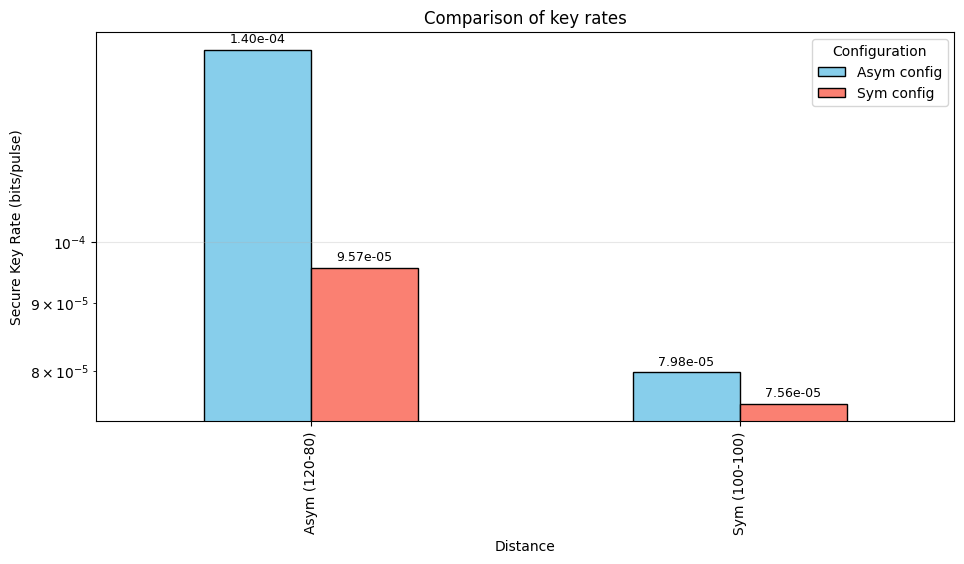


Configuration parameters

Symmetric config:
  mu_x = 0.15
  mu_y_A = 0.40, mu_y_B = 0.40
  mu_z_A = 0.55, mu_z_B = 0.55
  p_x   = 0.05
  p_y_A = 0.05, p_y_B = 0.05
  p_z_A = 0.20, p_z_B = 0.20

Asymmetric config:
  mu_x = 0.20
  mu_y_A = 0.35, mu_y_B = 0.40
  mu_z_A = 0.45, mu_z_B = 0.50
  p_x   = 0.05
  p_y_A = 0.04, p_y_B = 0.06
  p_z_A = 0.16, p_z_B = 0.24


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# ------------------------------------------------------------
# 1. Assume key_rate_asymmetric and helpers are defined.
# ------------------------------------------------------------

# ------------------------------------------------------------
# 2. Define configurations
# ------------------------------------------------------------
config_sym = {
    'mu_x': 0.15,
    'mu_y_A': 0.40, 'mu_y_B': 0.40,
    'p_y_A': 0.05, 'p_y_B': 0.05,
    'mu_z_A': 0.55, 'mu_z_B': 0.55,
    'p_z_A': 0.20, 'p_z_B': 0.20,
    'p_x': 0.05
}

config_asym = {
    'mu_x': 0.20,
    'mu_y_A': 0.35, 'mu_y_B': 0.40,
    'p_y_A': 0.04, 'p_y_B': 0.06,
    'mu_z_A': 0.45, 'mu_z_B': 0.50,
    'p_z_A': 0.16, 'p_z_B': 0.24,
    'p_x': 0.05
}

# ------------------------------------------------------------
# 3. Fixed distances
# ------------------------------------------------------------
distances = {
    'Sym (100-100)': (100.0, 100.0),
    'Asym (120-80)': (120.0, 80.0)
}

# ------------------------------------------------------------
# 4. Compute key rates
# ------------------------------------------------------------
results = []
for dist_label, (L_A, L_B) in distances.items():
    for config_label, cfg in [('Sym config', config_sym), ('Asym config', config_asym)]:
        R = key_rate_asymmetric(
            L_A, L_B,
            mu_x_A=cfg['mu_x'], mu_x_B=cfg['mu_x'],
            mu_y_A=cfg['mu_y_A'], mu_y_B=cfg['mu_y_B'],
            p_y_A=cfg['p_y_A'], p_y_B=cfg['p_y_B'],
            mu_z_A=cfg['mu_z_A'], mu_z_B=cfg['mu_z_B'],
            p_z_A=cfg['p_z_A'], p_z_B=cfg['p_z_B'],
            p_x=cfg['p_x'],
            p_v_A=None, p_v_B=None,
            N=1e13, alpha=0.165, Y0=1e-8, ed=0.03,
            f=1.16, epsilon=1e-10,
            E_Z_before=0.25, E_Z_after=0.003
        )
        results.append({
            'Distance': dist_label,
            'Config': config_label,
            'L_A': L_A,
            'L_B': L_B,
            'Key rate': R
        })

# Create DataFrame
df = pd.DataFrame(results)

# ------------------------------------------------------------
# 5. Print table
# ------------------------------------------------------------
print("\n" + "="*60)
print("Key rates for different combinations")
print("="*60)
print(df.to_string(index=False))

# ------------------------------------------------------------
# 6. Grouped bar chart
# ------------------------------------------------------------
# Pivot the DataFrame for grouped bars
pivot = df.pivot(index='Distance', columns='Config', values='Key rate')

# Plot
fig, ax = plt.subplots(figsize=(10, 6))
pivot.plot(kind='bar', ax=ax, color=['skyblue', 'salmon'], edgecolor='black')
ax.set_ylabel('Secure Key Rate (bits/pulse)')
ax.set_title('Comparison of key rates')
ax.set_yscale('log')
ax.grid(axis='y', alpha=0.3)
ax.legend(title='Configuration')

# Add value labels on top of bars
for container in ax.containers:
    ax.bar_label(container, fmt='%.2e', fontsize=9, padding=3)

# Adjust layout to avoid warning
plt.tight_layout(pad=2.0)
plt.show()

# ------------------------------------------------------------
# 7. Print configuration parameters
# ------------------------------------------------------------
print("\n" + "="*20)
print("Configuration parameters")
print("="*20)
for label, cfg in [('Symmetric config', config_sym), ('Asymmetric config', config_asym)]:
    print(f"\n{label}:")
    print(f"  mu_x = {cfg['mu_x']:.2f}")
    print(f"  mu_y_A = {cfg['mu_y_A']:.2f}, mu_y_B = {cfg['mu_y_B']:.2f}")
    print(f"  mu_z_A = {cfg['mu_z_A']:.2f}, mu_z_B = {cfg['mu_z_B']:.2f}")
    print(f"  p_x   = {cfg['p_x']:.2f}")
    print(f"  p_y_A = {cfg['p_y_A']:.2f}, p_y_B = {cfg['p_y_B']:.2f}")
    print(f"  p_z_A = {cfg['p_z_A']:.2f}, p_z_B = {cfg['p_z_B']:.2f}")

This section shows that, a selection of **asymmetric channel** and **asymmetric distance** offers the best key rate.